<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/VB-day4/VB_Day4_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision 기본 모델 Day 4 — 객체 탐지 기본: bbox · IoU · NMS · mAP · YOLO

**온디바이스 AI · Vision 기본 모델 4/5 · 11/2(월)** · Google Colab (GPU 런타임) · PyTorch · ultralytics · Penn-Fudan · 보행자 영상

분류기는 "**무엇이**" 만 답합니다. 오늘은 "**무엇이 어디에**" — 객체 탐지로 넘어갑니다.

오늘의 목표

1. 분류기로 "사람이 몇 명?" 을 풀기 어려운 이유를 계산으로 확인하고, 탐지의 출력 (클래스 · 박스 · 점수) 을 정의한다.
2. bbox 좌표 표현 (xyxy · xywh · 정규화 cxcywh) 과 COCO 어노테이션 포맷을 다룬다.
3. 탐지 후처리 **IoU · NMS** 와 평가 지표 **Precision · Recall · AP · mAP** 를 NumPy 로 직접 구현하고 `torchvision` 결과와 맞춰 본다.
4. 2-stage (Faster R-CNN) 와 1-stage (SSD · YOLO) 탐지기의 구조와 속도-정확도 trade-off 를 이해한다.
5. YOLOv8 의 원시 출력 텐서 (1, 84, 8400) 를 직접 디코드해서 라이브러리 결과와 같은지 확인한다.
6. 녹화 영상에 탐지기를 적용해 **사람 수를 세는 결과 영상**을 만들고, 단계별 시간을 잰다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 1~3 복습 퀴즈 · 분류기로 "사람이 몇 명?" |
| 2 | 10:00–10:50 | 탐지 문제 정의 — bbox 표현 · COCO 포맷 |
| 3 | 11:00–11:50 | IoU · NMS |
| 4 | 13:00–13:50 | 평가 지표 — Precision · Recall · AP · mAP |
| 5 | 14:00–14:50 | 2-stage vs 1-stage — Faster R-CNN · SSD |
| 6 | 15:00–15:50 | YOLO 구조 — grid · 출력 텐서 디코드 |
| 7 | 16:00–16:50 | 영상 탐지 파이프라인 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 직접 만든 mAP 로 탐지기 2종 평가 + 영상 인원 카운트 (이 노트북 맨 끝) |

**노트북 사용법**

1. *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행하고, 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다.
3. 막히면 **🔒 정답 보기** 셀을 실행하세요. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
4. 8교시 미니 프로젝트는 이 노트북 맨 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/VB_Day4.pdf](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/VB_Day4.pdf) |

**오늘의 데이터**

- **Penn-Fudan Pedestrian** — 보행자 사진 170장, 423명에 정답 박스 · 마스크 (마스크는 Day 5 세그멘테이션에서 씁니다)
- **보행자 녹화 영상** `people.mp4` — 768×576, 10 FPS, 795 프레임 (OpenCV 공개 샘플). 카메라 대신 씁니다.
- **사전학습 탐지기** — YOLOv8n · YOLOv8s (ultralytics), Faster R-CNN · SSDLite (torchvision). 모두 COCO 80 클래스로 학습되어 있어 'person' 을 바로 찾습니다. 직접 학습 (커스텀 데이터) 은 YOLOv8 Edge 모델 과목 (12/11~) 에서 합니다.

In [ ]:
# ▶ 설치 셀 — ultralytics (YOLOv8) 설치. 처음 한 번, 약 30초
%pip install -q ultralytics

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, re, glob, time, json, copy, base64, inspect, subprocess, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torchvision
from IPython.display import HTML, display

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6, 4)
torch.manual_seed(0)
rng = np.random.default_rng(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4"
PF = "PennFudanPed"

def load_rgb(path):
    """이미지 파일 → RGB uint8 (H, W, 3). OpenCV 는 BGR 로 읽으므로 바꿔 준다 (Day 1)."""
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)

def draw_boxes(img, boxes, color=(0, 255, 0), labels=None, thick=2):
    """박스 (N, 4) xyxy 를 그린 사본을 돌려준다. labels 는 문자열 목록."""
    out = img.copy()
    for k, b in enumerate(np.asarray(boxes).reshape(-1, 4)):
        x1, y1, x2, y2 = [int(round(v)) for v in b]
        cv2.rectangle(out, (x1, y1), (x2, y2), color, thick)
        if labels is not None:
            cv2.putText(out, str(labels[k]), (x1, max(y1 - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
    return out

def show(imgs, titles=None, cols=4, size=3.2):
    imgs = list(imgs); rows = (len(imgs) + cols - 1) // cols
    plt.figure(figsize=(size * min(cols, len(imgs)), size * rows))
    for i, im in enumerate(imgs):
        plt.subplot(rows, min(cols, len(imgs)), i + 1); plt.imshow(im); plt.axis("off")
        if titles is not None: plt.title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()

print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", device)

In [ ]:
# ▶ 데이터 셀 — Penn-Fudan (약 50 MB) 과 보행자 영상 (약 4 MB) 받기
if not os.path.exists(f"{PF}/PNGImages"):
    try:
        urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "PennFudanPed.zip")
        zipfile.ZipFile("PennFudanPed.zip").extractall(".")
    except Exception as e:                      # 기본 주소가 막히면 GitHub 미러
        print("기본 주소 실패 → GitHub 미러에서 받습니다:", e)
        subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/swallan/PennFudanPed.git", PF], check=True)
VIDEO = "people.mp4"
if not os.path.exists(VIDEO):
    try:
        urllib.request.urlretrieve(f"{RAW}/data/people.mp4", VIDEO)
    except Exception as e:                      # 저장소가 막히면 OpenCV 원본 (avi)
        print("영상 기본 주소 실패 → OpenCV 원본:", e)
        VIDEO = "people.avi"
        urllib.request.urlretrieve("https://raw.githubusercontent.com/opencv/opencv/master/samples/data/vtest.avi", VIDEO)
print(len(glob.glob(f"{PF}/PNGImages/*.png")), "장 |", VIDEO, os.path.getsize(VIDEO) // 1024, "KB")

## 1교시 — 복습 퀴즈 · 분류기로 "사람이 몇 명?"

**09:00–09:15 Day 1~3 복습 퀴즈** (Google Forms 20문항 — 강사가 링크를 공유합니다. 금요일 특강으로 하루 쉬었으니 1~3일차를 함께 복습합니다.)

### 오늘의 질문

Day 3 의 MobileNetV3 분류기는 사진 한 장에 **라벨 하나** 를 냅니다. 그런데 현장 안전에서 필요한 것은

- 이 화면에 **사람이 몇 명** 있나?
- 각 사람이 **어디에** 있나? (위험구역 안인가?)

| 과제 | 입력 | 출력 |
|---|---|---|
| 분류 (Day 1~3) | 이미지 | 클래스 1개 (+ 확률) |
| **탐지 (오늘)** | 이미지 | 물체마다 **(클래스, 박스, 점수)** — 개수가 이미지마다 다르다 |
| 세그멘테이션 · 포즈 (Day 5) | 이미지 | 픽셀마다 클래스 · 관절 좌표 |

> 🎬 **애니메이션** [D4-1 분류 vs 탐지](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

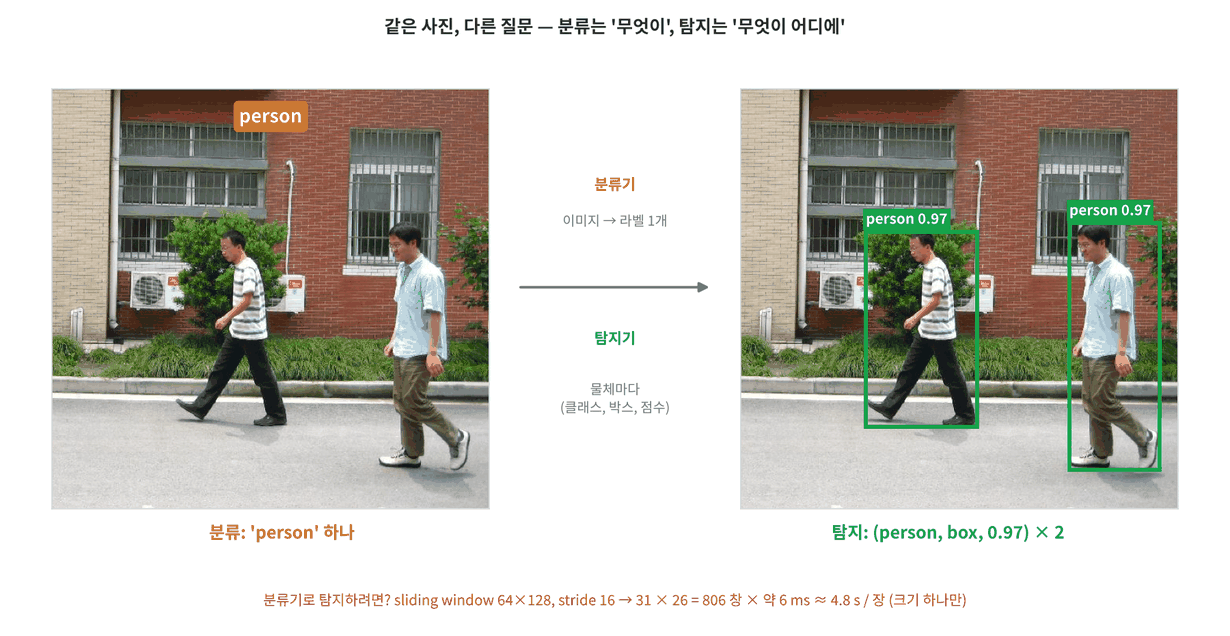

In [ ]:
#@title 🖼 그림 — 분류와 탐지의 출력 비교
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f1_cls_vs_det.png", embed=True, width=820))

### Penn-Fudan 데이터 살펴보기

정답은 이미지마다 텍스트 파일 하나에 들어 있습니다.

```
Bounding box for object 1 "PASpersonWalking" (Xmin, Ymin) - (Xmax, Ymax) : (160, 182) - (302, 431)
```

**문제 1-1** 어노테이션 파일에서 박스 좌표만 뽑는 `parse_annotation` 을 완성하세요. 정규식이 `(x1, y1) - (x2, y2)` 네 숫자를 찾아 줍니다. 결과는 (사람 수, 4) 배열입니다.

In [ ]:
def parse_annotation(path):
    text = open(path, encoding="latin-1").read()
    pairs = re.findall(r"\((\d+), (\d+)\) - \((\d+), (\d+)\)", text)      # [('160', '182', '302', '431'), ...]
    return np.array(____, dtype=np.float32).reshape(-1, ____)

img_paths = sorted(glob.glob(f"{PF}/PNGImages/*.png"))
ann_path = lambda p: p.replace("PNGImages", "Annotation").replace(".png", ".txt")
gts = [parse_annotation(____) for p in img_paths]
print(len(img_paths), "장 |", os.path.basename(img_paths[0]), "\n", gts[0])

In [ ]:
assert len(img_paths) == 170 and gts[0].tolist() == [[160, 182, 302, 431], [420, 171, 535, 486]]; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmRlZiBwYXJzZV9hbm5vdGF0aW9uKHBhdGgpOgogICAgdGV4dCA9IG9w"
    "ZW4ocGF0aCwgZW5jb2Rpbmc9ImxhdGluLTEiKS5yZWFkKCkKICAgIHBhaXJzID0gcmUuZmluZGFsbChyIlwoKFxk"
    "KyksIChcZCspXCkgLSBcKChcZCspLCAoXGQrKVwpIiwgdGV4dCkgICAgICAjIFsoJzE2MCcsICcxODInLCAnMzAy"
    "JywgJzQzMScpLCAuLi5dCiAgICByZXR1cm4gbnAuYXJyYXkocGFpcnMsIGR0eXBlPW5wLmZsb2F0MzIpLnJlc2hh"
    "cGUoLTEsIDQpCgppbWdfcGF0aHMgPSBzb3J0ZWQoZ2xvYi5nbG9iKGYie1BGfS9QTkdJbWFnZXMvKi5wbmciKSkK"
    "YW5uX3BhdGggPSBsYW1iZGEgcDogcC5yZXBsYWNlKCJQTkdJbWFnZXMiLCAiQW5ub3RhdGlvbiIpLnJlcGxhY2Uo"
    "Ii5wbmciLCAiLnR4dCIpCmd0cyA9IFtwYXJzZV9hbm5vdGF0aW9uKGFubl9wYXRoKHApKSBmb3IgcCBpbiBpbWdf"
    "cGF0aHNdCnByaW50KGxlbihpbWdfcGF0aHMpLCAi7J6lIHwiLCBvcy5wYXRoLmJhc2VuYW1lKGltZ19wYXRoc1sw"
    "XSksICJcbiIsIGd0c1swXSkKCvCfkqEg7ZW07ISkCmByZS5maW5kYWxsYCDsnYAg6rSE7Zi4IOq3uOujuSA06rCc"
    "66W8IO2KnO2UjOuhnCDrj4zroKTspI3ri4jri6QuIOusuOyekOyXtCDtipztlIwg66qp66Gd64+EIGBucC5hcnJh"
    "eSguLi4sIGR0eXBlPW5wLmZsb2F0MzIpYCDroZwg67CU66GcIOyIq+yekCDrsLDsl7TsnbQg65Cp64uI64ukLiDs"
    "gqzrnozsnbQgMeuqheydtOuptCAoMSwgNCksIDDrqoXsnbTslrTrj4QgcmVzaGFwZSgtMSwgNCkg642V67aE7JeQ"
    "ICgwLCA0KSDrqqjslpHsnbQg7Jyg7KeA65Cp64uI64ukLg=="
).decode("utf-8"))

**문제 1-2** 데이터셋 통계를 내세요 — 전체 사람 수, 이미지당 사람 수 분포 (`np.bincount`), 박스 크기 분포.

In [ ]:
counts = np.array([len(g) for g in gts])
print("전체", counts.____, "명 | 이미지당 최대", counts.max(), "명")
print("사람 수별 이미지 장수:", np.bincount(____))       # 인덱스 = 사람 수
all_boxes = np.concatenate(gts)
bw, bh = all_boxes[:, 2] - all_boxes[:, 0], all_boxes[:, 3] - all_boxes[:, 1]
plt.figure(figsize=(9, 3.2))
plt.subplot(1, 2, 1); plt.bar(range(counts.max() + 1), np.bincount(counts)); plt.xlabel("people per image"); plt.ylabel("images")
plt.subplot(1, 2, 2); plt.scatter(bw, bh, s=8); plt.xlabel("box width (px)"); plt.ylabel("box height (px)")
plt.tight_layout(); plt.show()

In [ ]:
assert counts.sum() == 423 and len(all_boxes) == 423; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACmNvdW50cyA9IG5wLmFycmF5KFtsZW4oZykgZm9yIGcgaW4gZ3RzXSkK"
    "cHJpbnQoIuyghOyytCIsIGNvdW50cy5zdW0oKSwgIuuqhSB8IOydtOuvuOyngOuLuSDstZzrjIAiLCBjb3VudHMu"
    "bWF4KCksICLrqoUiKQpwcmludCgi7IKs656MIOyImOuzhCDsnbTrr7jsp4Ag7J6l7IiYOiIsIG5wLmJpbmNvdW50"
    "KGNvdW50cykpICAgICAgICMg7J24642x7IqkID0g7IKs656MIOyImAphbGxfYm94ZXMgPSBucC5jb25jYXRlbmF0"
    "ZShndHMpCmJ3LCBiaCA9IGFsbF9ib3hlc1s6LCAyXSAtIGFsbF9ib3hlc1s6LCAwXSwgYWxsX2JveGVzWzosIDNd"
    "IC0gYWxsX2JveGVzWzosIDFdCnBsdC5maWd1cmUoZmlnc2l6ZT0oOSwgMy4yKSkKcGx0LnN1YnBsb3QoMSwgMiwg"
    "MSk7IHBsdC5iYXIocmFuZ2UoY291bnRzLm1heCgpICsgMSksIG5wLmJpbmNvdW50KGNvdW50cykpOyBwbHQueGxh"
    "YmVsKCJwZW9wbGUgcGVyIGltYWdlIik7IHBsdC55bGFiZWwoImltYWdlcyIpCnBsdC5zdWJwbG90KDEsIDIsIDIp"
    "OyBwbHQuc2NhdHRlcihidywgYmgsIHM9OCk7IHBsdC54bGFiZWwoImJveCB3aWR0aCAocHgpIik7IHBsdC55bGFi"
    "ZWwoImJveCBoZWlnaHQgKHB4KSIpCnBsdC50aWdodF9sYXlvdXQoKTsgcGx0LnNob3coKQoK8J+SoSDtlbTshKQK"
    "MTcw7J6l7JeQIDQyM+uqhSwg7J2066+47KeA64u5IDF+OOuqheyeheuLiOuLpC4g6rCZ7J2AIOu2hOulmOq4sOuh"
    "nOuKlCAn7IKs656MIOyeiOydjCcg6rmM7KeA66eMIOunkO2VoCDsiJgg7J6I6rOgLCAn66qHIOuqhScgwrcgJ+yW"
    "tOuUlCcg64qUIOuLte2VoCDsiJgg7JeG7Iq164uI64ukLiDrsJXsiqQg64aS7J206rCAIOuMgOu2gOu2hCDsiJjr"
    "sLEg7ZS97IWAIOKAlCDsgqzrnozsnbQg7YGs6rKMIOywje2ejCDrjbDsnbTthLDsnoXri4jri6QgKDjqtZDsi5wg"
    "7ZW07ISd7JeQIOyUgeuLiOuLpCku"
).decode("utf-8"))

**문제 1-3** 분류기로 탐지를 흉내 내는 가장 단순한 방법은 **sliding window** — 창을 조금씩 옮기며 창마다 분류기를 돌리는 것입니다. 64×128 창을 stride 16 으로 옮길 때 첫 번째 이미지 (559×536) 에서 창이 몇 개인지 세세요.

In [ ]:
def n_windows(W, H, win=(64, 128), stride=16):
    nx = (W - win[0]) // stride + ____
    ny = (____) // stride + 1
    return nx * ny

img0 = load_rgb(img_paths[0]); H0, W0 = img0.shape[:2]
nw = n_windows(W0, H0)
print(f"{W0}×{H0} 이미지 → 창 {nw}개 → 창마다 6 ms 분류기면 {nw * 6 / 1000:.1f} 초 / 장 (크기 1가지만!)")

In [ ]:
assert (W0, H0) == (559, 536) and nw == 806; print("✅")

In [ ]:
#@title 🔒 정답 보기 1-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTMg4pSA4pSACmRlZiBuX3dpbmRvd3MoVywgSCwgd2luPSg2NCwgMTI4KSwgc3RyaWRl"
    "PTE2KToKICAgIG54ID0gKFcgLSB3aW5bMF0pIC8vIHN0cmlkZSArIDEKICAgIG55ID0gKEggLSB3aW5bMV0pIC8v"
    "IHN0cmlkZSArIDEKICAgIHJldHVybiBueCAqIG55CgppbWcwID0gbG9hZF9yZ2IoaW1nX3BhdGhzWzBdKTsgSDAs"
    "IFcwID0gaW1nMC5zaGFwZVs6Ml0KbncgPSBuX3dpbmRvd3MoVzAsIEgwKQpwcmludChmIntXMH3Dl3tIMH0g7J20"
    "66+47KeAIOKGkiDssL0ge253feqwnCDihpIg7LC966eI64ukIDYgbXMg67aE66WY6riw66m0IHtudyAqIDYgLyAx"
    "MDAwOi4xZn0g7LSIIC8g7J6lICjtgazquLAgMeqwgOyngOunjCEpIikKCvCfkqEg7ZW07ISkCuqwgOuhnCAoNTU5"
    "4oiSNjQpLy8xNisxID0gMzEsIOyEuOuhnCAoNTM24oiSMTI4KS8vMTYrMSA9IDI2IOKGkiA4MDbqsJwuIERheSAz"
    "IE1vYmlsZU5ldFYzLVMgKDk2IOyeheugpSkg7J2YIENQVSDsi6Ttlokg7JiIIOyVvSA2IG1zIOuhnCDqs4TsgrDt"
    "lZjrqbQg7J2066+47KeAIO2VnCDsnqXsl5Ag7JW9IDQuOOy0iCDigJQg6rKM64uk6rCAIOyCrOuejCDtgazquLDq"
    "sIAg7KCc6rCB6rCB7J206528IOywvSDtgazquLDrj4Qg7Jes65+sIOqwnCDtlYTsmpTtlZjqs6AsIOqyuey5mOuK"
    "lCDssL3snbQg6rCZ7J2AIOyCrOuejOydhCDsl6zrn6wg67KIIOywvuyKteuLiOuLpCAo4oaSIDPqtZDsi5wgTk1T"
    "KS4g7YOQ7KeA6riw64qUICoq7ZWcIOuyiOydmCBmb3J3YXJkKiog66GcIOuqqOuToCDsnITsuZjsnZgg67CV7Iqk"
    "7JmAIOygkOyImOulvCDrg4Xri4jri6Qu"
).decode("utf-8"))

In [ ]:
# 창 몇 개를 그려 보기 (stride 를 크게 해서 일부만)
vis = img0.copy()
for y in range(0, H0 - 128 + 1, 96):
    for x in range(0, W0 - 64 + 1, 96):
        cv2.rectangle(vis, (x, y), (x + 64, y + 128), (255, 200, 0), 1)
show([draw_boxes(img0, gts[0]), vis], ["ground truth: 2 people", "sliding windows (stride 96 shown)"], cols=2, size=4.5)

#### 📌 1교시 정리

- 탐지 = 물체마다 (클래스, 박스, 점수). 개수는 이미지마다 다르다.
- Penn-Fudan: 170장 · 423명. 정답 박스는 xyxy 픽셀 좌표.
- sliding window 는 창 수백~수천 개 × 분류기 → 너무 느리다. 탐지기는 한 번에 예측한다.

## 2교시 — 탐지 문제 정의: bbox 표현 · COCO 포맷

이미지 좌표는 **왼쪽 위가 원점**, x 는 오른쪽, **y 는 아래쪽**으로 커집니다. 같은 박스를 세 가지로 씁니다.

| 표현 | 값 | 쓰는 곳 |
|---|---|---|
| **xyxy** | (x1, y1, x2, y2) 왼쪽 위 · 오른쪽 아래 | Pascal VOC, torchvision, NMS 계산 |
| **xywh** | (x, y, w, h) 왼쪽 위 + 너비 · 높이 | COCO 어노테이션 |
| **cxcywh 정규화** | (cx/W, cy/H, w/W, h/H) 0~1 | YOLO 라벨 파일 · YOLO 출력 (픽셀 단위) |

정규화 좌표는 이미지 크기를 바꿔도 값이 그대로라서 resize 가 많은 학습에 편합니다.

> 🎬 **애니메이션** [D4-2 bbox 좌표계](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

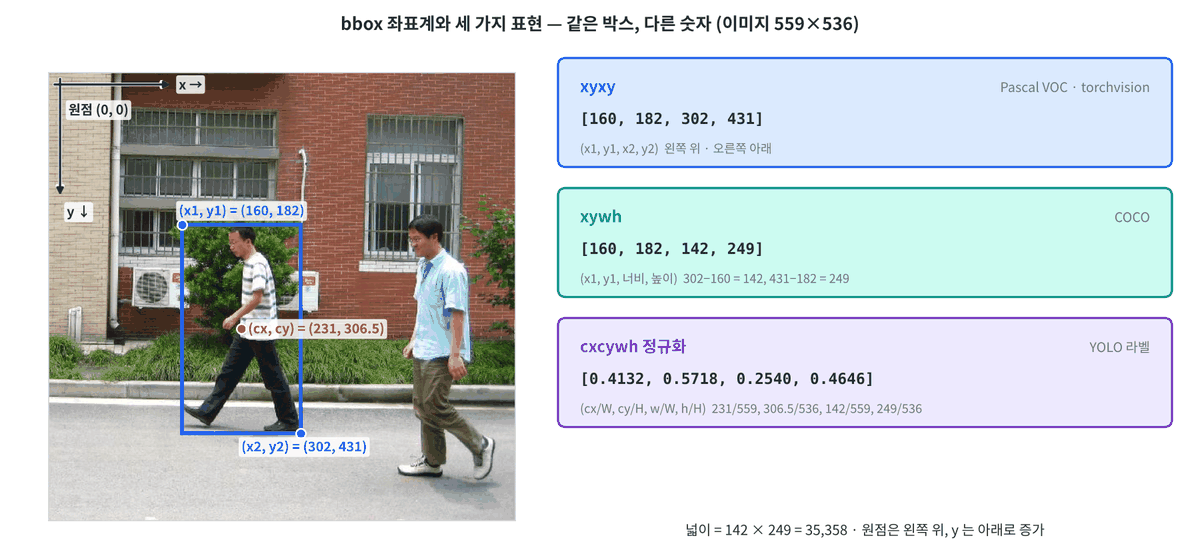

In [ ]:
#@title 🖼 그림 — 같은 박스의 세 가지 표현
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f2_bbox_formats.png", embed=True, width=800))

**문제 2-1** 좌표 변환 함수 네 개를 완성하세요. 모두 (N, 4) 배열도 받을 수 있도록 `[..., k]` 인덱싱을 씁니다.

In [ ]:
def xyxy_to_xywh(b):
    b = np.asarray(b, float)
    return np.stack([b[..., 0], b[..., 1], b[..., 2] - b[..., 0], ____], -1)

def xywh_to_xyxy(b):
    b = np.asarray(b, float)
    return np.stack([b[..., 0], b[..., 1], b[..., 0] + b[..., 2], b[..., 1] + b[..., 3]], -1)

def xyxy_to_cxcywh_norm(b, W, H):
    b = np.asarray(b, float)
    w, h = b[..., 2] - b[..., 0], b[..., 3] - b[..., 1]
    cx, cy = b[..., 0] + w / ____, b[..., 1] + h / 2
    return np.stack([cx / W, cy / ____, w / W, h / H], -1)

def cxcywh_norm_to_xyxy(b, W, H):
    b = np.asarray(b, float)
    cx, cy, w, h = b[..., 0] * W, b[..., 1] * H, b[..., 2] * W, b[..., 3] * H
    return np.stack([cx - w / 2, cy - h / 2, ____, cy + h / 2], -1)

box = gts[0][0]
print("xyxy", box, "| xywh", xyxy_to_xywh(box), "| cxcywh 정규화", xyxy_to_cxcywh_norm(box, W0, H0))

In [ ]:
assert np.allclose(xyxy_to_xywh(box), [160, 182, 142, 249])
assert np.allclose(xyxy_to_cxcywh_norm(box, 559, 536), [231 / 559, 306.5 / 536, 142 / 559, 249 / 536])
assert all(np.allclose(cxcywh_norm_to_xyxy(xyxy_to_cxcywh_norm(g, 640, 480), 640, 480), g, atol=1e-4) for g in gts)
assert all(np.allclose(xywh_to_xyxy(xyxy_to_xywh(g)), g) for g in gts); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiB4eXh5X3RvX3h5d2goYik6CiAgICBiID0gbnAuYXNhcnJheShi"
    "LCBmbG9hdCkKICAgIHJldHVybiBucC5zdGFjayhbYlsuLi4sIDBdLCBiWy4uLiwgMV0sIGJbLi4uLCAyXSAtIGJb"
    "Li4uLCAwXSwgYlsuLi4sIDNdIC0gYlsuLi4sIDFdXSwgLTEpCgpkZWYgeHl3aF90b194eXh5KGIpOgogICAgYiA9"
    "IG5wLmFzYXJyYXkoYiwgZmxvYXQpCiAgICByZXR1cm4gbnAuc3RhY2soW2JbLi4uLCAwXSwgYlsuLi4sIDFdLCBi"
    "Wy4uLiwgMF0gKyBiWy4uLiwgMl0sIGJbLi4uLCAxXSArIGJbLi4uLCAzXV0sIC0xKQoKZGVmIHh5eHlfdG9fY3hj"
    "eXdoX25vcm0oYiwgVywgSCk6CiAgICBiID0gbnAuYXNhcnJheShiLCBmbG9hdCkKICAgIHcsIGggPSBiWy4uLiwg"
    "Ml0gLSBiWy4uLiwgMF0sIGJbLi4uLCAzXSAtIGJbLi4uLCAxXQogICAgY3gsIGN5ID0gYlsuLi4sIDBdICsgdyAv"
    "IDIsIGJbLi4uLCAxXSArIGggLyAyCiAgICByZXR1cm4gbnAuc3RhY2soW2N4IC8gVywgY3kgLyBILCB3IC8gVywg"
    "aCAvIEhdLCAtMSkKCmRlZiBjeGN5d2hfbm9ybV90b194eXh5KGIsIFcsIEgpOgogICAgYiA9IG5wLmFzYXJyYXko"
    "YiwgZmxvYXQpCiAgICBjeCwgY3ksIHcsIGggPSBiWy4uLiwgMF0gKiBXLCBiWy4uLiwgMV0gKiBILCBiWy4uLiwg"
    "Ml0gKiBXLCBiWy4uLiwgM10gKiBICiAgICByZXR1cm4gbnAuc3RhY2soW2N4IC0gdyAvIDIsIGN5IC0gaCAvIDIs"
    "IGN4ICsgdyAvIDIsIGN5ICsgaCAvIDJdLCAtMSkKCmJveCA9IGd0c1swXVswXQpwcmludCgieHl4eSIsIGJveCwg"
    "InwgeHl3aCIsIHh5eHlfdG9feHl3aChib3gpLCAifCBjeGN5d2gg7KCV6rec7ZmUIiwgeHl4eV90b19jeGN5d2hf"
    "bm9ybShib3gsIFcwLCBIMCkpCgrwn5KhIO2VtOyEpApbMTYwLCAxODIsIDMwMiwgNDMxXSDihpIgeHl3aCBbMTYw"
    "LCAxODIsIDE0MiwgMjQ5XSDihpIg7KSR7IusICgyMzEsIDMwNi41KSDihpIg7KCV6rec7ZmUIFswLjQxMzIsIDAu"
    "NTcxOCwgMC4yNTQwLCAwLjQ2NDZdLiDrs4DtmZgg4oaSIOyXreuzgO2ZmOydhCDtlZjrqbQg7JuQ656YIOqwkuyd"
    "tCDrgpjsmYDslbwg7ZWp64uI64ukICjtmZXsnbgg7IWA7J2YIOyZleuztSDqsoDsgqwpLiDsooztkZzqs4Trpbwg"
    "7Ze36rCI66as66m0IOuwleyKpOqwgCDsl4nrmrHtlZwg6rOz7JeQIOq3uOugpOyngOuvgOuhnCwg7IOIIOuNsOyd"
    "tO2EsOulvCDrsJvsnLzrqbQgKirtla3sg4Eg6re466Ck7IScIO2ZleyduCoq7ZWp64uI64ukICjri6TsnYwg66y4"
    "7KCcKS4="
).decode("utf-8"))

**문제 2-2** 정답 박스를 그려서 확인하세요. 사람이 많은 이미지 4장을 골라 박스와 사람 수를 표시합니다.

In [ ]:
idx4 = np.argsort(-counts, kind="stable")[:4]            # 사람이 많은 순서로 4장
vis4 = [draw_boxes(load_rgb(img_paths[i]), ____, labels=[f"#{k + 1}" for k in range(len(gts[i]))]) for i in idx4]
show(vis4, [f"{os.path.basename(img_paths[i])}: {____} people" for i in idx4])

In [ ]:
assert len(vis4) == 4 and counts[idx4].min() >= 5; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmlkeDQgPSBucC5hcmdzb3J0KC1jb3VudHMsIGtpbmQ9InN0YWJsZSIp"
    "Wzo0XSAgICAgICAgICAgICMg7IKs656M7J20IOunjuydgCDsiJzshJzroZwgNOyepQp2aXM0ID0gW2RyYXdfYm94"
    "ZXMobG9hZF9yZ2IoaW1nX3BhdGhzW2ldKSwgZ3RzW2ldLCBsYWJlbHM9W2YiI3trICsgMX0iIGZvciBrIGluIHJh"
    "bmdlKGxlbihndHNbaV0pKV0pIGZvciBpIGluIGlkeDRdCnNob3codmlzNCwgW2Yie29zLnBhdGguYmFzZW5hbWUo"
    "aW1nX3BhdGhzW2ldKX06IHtsZW4oZ3RzW2ldKX0gcGVvcGxlIiBmb3IgaSBpbiBpZHg0XSkKCvCfkqEg7ZW07ISk"
    "CuyCrOynhOydhCDsnpDshLjtnogg67O066m0ICoq7KCV64u1IOuwleyKpOqwgCDsl4bripQg7IKs656MKirrj4Qg"
    "7J6I7Iq164uI64ukIOKAlCBQZW5uLUZ1ZGFuIOydgCDrhIjrrLQg7J6R6rGw64KYIOunjuydtCDqsIDroKTsp4Qg"
    "7IKs656M7J2AIOygleuLteyXkOyEnCDrupDsirXri4jri6QuIO2DkOyngOq4sOqwgCDqt7gg7IKs656M7J2EIOun"
    "nuqyjCDssL7slYTrj4Qg7Y+J6rCA7JeQ7ISc64qUICfsmKTtg5AgKEZQKScg7Jy866GcIOqzhOyCsOuQqeuLiOuL"
    "pC4gNOq1kOyLnCDCtyA46rWQ7Iuc7JeQ7IScIOydtCDsoJDsnYQg64uk7IucIOu0heuLiOuLpC4="
).decode("utf-8"))

### COCO 어노테이션 포맷

탐지 데이터셋 대부분은 COCO JSON 형식을 씁니다. 학습 · 평가 도구 (pycocotools, torchvision, ultralytics 변환기 등) 가 이 형식을 읽습니다.

```json
{"images":      [{"id": 1, "file_name": "FudanPed00001.png", "width": 559, "height": 536}, ...],
 "annotations": [{"id": 1, "image_id": 1, "category_id": 1, "bbox": [160, 182, 142, 249], "area": 35358, "iscrowd": 0}, ...],
 "categories":  [{"id": 1, "name": "person"}]}
```

`bbox` 는 **xywh** 입니다. 이미지 · 박스 · 클래스가 id 로 연결됩니다.

**문제 2-3** Penn-Fudan 정답을 COCO 형식 딕셔너리로 바꿔 `pennfudan_coco.json` 으로 저장하세요.

In [ ]:
coco = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "person"}]}
ann_id = 1
for img_id, (p, g) in enumerate(zip(img_paths, gts), start=1):
    h, w = cv2.imread(p).shape[:2]
    coco["images"].append({"id": img_id, "file_name": os.path.basename(p), "width": w, "height": h})
    for b in ____:
        coco["annotations"].append({"id": ann_id, "image_id": ____, "category_id": 1,
                                    "bbox": [float(v) for v in b], "area": float(____), "iscrowd": 0})
        ann_id += 1
json.dump(coco, open("pennfudan_coco.json", "w"))
print(len(coco["images"]), "images |", len(coco["annotations"]), "annotations |", coco["annotations"][0])

In [ ]:
a0 = coco["annotations"][0]
assert len(coco["annotations"]) == 423 and a0["bbox"] == [160, 182, 142, 249] and a0["area"] == 35358 and a0["image_id"] == 1
assert len({a["id"] for a in coco["annotations"]}) == 423; print("✅")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmNvY28gPSB7ImltYWdlcyI6IFtdLCAiYW5ub3RhdGlvbnMiOiBbXSwg"
    "ImNhdGVnb3JpZXMiOiBbeyJpZCI6IDEsICJuYW1lIjogInBlcnNvbiJ9XX0KYW5uX2lkID0gMQpmb3IgaW1nX2lk"
    "LCAocCwgZykgaW4gZW51bWVyYXRlKHppcChpbWdfcGF0aHMsIGd0cyksIHN0YXJ0PTEpOgogICAgaCwgdyA9IGN2"
    "Mi5pbXJlYWQocCkuc2hhcGVbOjJdCiAgICBjb2NvWyJpbWFnZXMiXS5hcHBlbmQoeyJpZCI6IGltZ19pZCwgImZp"
    "bGVfbmFtZSI6IG9zLnBhdGguYmFzZW5hbWUocCksICJ3aWR0aCI6IHcsICJoZWlnaHQiOiBofSkKICAgIGZvciBi"
    "IGluIHh5eHlfdG9feHl3aChnKToKICAgICAgICBjb2NvWyJhbm5vdGF0aW9ucyJdLmFwcGVuZCh7ImlkIjogYW5u"
    "X2lkLCAiaW1hZ2VfaWQiOiBpbWdfaWQsICJjYXRlZ29yeV9pZCI6IDEsCiAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgICAgICJiYm94IjogW2Zsb2F0KHYpIGZvciB2IGluIGJdLCAiYXJlYSI6IGZsb2F0KGJbMl0gKiBi"
    "WzNdKSwgImlzY3Jvd2QiOiAwfSkKICAgICAgICBhbm5faWQgKz0gMQpqc29uLmR1bXAoY29jbywgb3BlbigicGVu"
    "bmZ1ZGFuX2NvY28uanNvbiIsICJ3IikpCnByaW50KGxlbihjb2NvWyJpbWFnZXMiXSksICJpbWFnZXMgfCIsIGxl"
    "bihjb2NvWyJhbm5vdGF0aW9ucyJdKSwgImFubm90YXRpb25zIHwiLCBjb2NvWyJhbm5vdGF0aW9ucyJdWzBdKQoK"
    "8J+SoSDtlbTshKQKQ09DTyDsnZggY2F0ZWdvcnkgaWQg64qUIDHrtoDthLAg7Iuc7J6R7ZWp64uI64ukICh0b3Jj"
    "aHZpc2lvbiDtg5Dsp4DquLDrj4QgMCA9IGJhY2tncm91bmQsIDEgPSBwZXJzb24pLiDrsJjrqbQgWU9MTyDripQg"
    "MOu2gO2EsCAoMCA9IHBlcnNvbikuIO2BtOuemOyKpCDrsojtmLgg7LK06rOE6rCAIOuPhOq1rOuniOuLpCDri6Tr"
    "pbTri6TripQg6rKD7J2EIOq4sOyWte2VmOyEuOyalCDigJQgNeq1kOyLnCAodG9yY2h2aXNpb246IGxhYmVsIDEp"
    "IOyZgCA26rWQ7IucIChZT0xPOiBjbGFzcyAwKSDsl5DshJwg67CU66GcIOunjOuCqeuLiOuLpC4="
).decode("utf-8"))

### 탐지기는 무엇을 학습하나

탐지기의 손실 = **분류 손실** (이 위치에 무엇이 있나 — cross-entropy) + **박스 회귀 손실** (박스를 얼마나 옮기고 늘려야 하나 — Smooth L1, 또는 IoU 를 직접 키우는 IoU 계열 손실).

Day 2 · 3 의 분류 학습에 '숫자 4개를 맞히는 회귀' 가 더해진 것입니다. 오늘은 학습 대신 **사전학습 탐지기**를 쓰고, 그 결과를 **후처리 · 평가**하는 코드를 직접 만듭니다.

#### 📌 2교시 정리

- xyxy (VOC · torchvision) · xywh (COCO) · cxcywh 정규화 (YOLO). 새 데이터는 반드시 그려서 확인.
- COCO JSON = images · annotations (bbox 는 xywh) · categories.
- 탐지 손실 = 분류 + 박스 회귀.

## 3교시 — IoU · NMS

### IoU (Intersection over Union)

두 박스가 얼마나 겹치는지 0~1 로 나타냅니다.

$$\text{IoU} = \frac{\text{교집합 넓이}}{\text{합집합 넓이}} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|}$$

교집합 박스: 왼쪽 위 = (max x1, max y1), 오른쪽 아래 = (min x2, min y2). 안 겹치면 폭이나 높이가 음수 → 0 으로 자릅니다.

IoU 는 탐지의 거의 모든 곳에 쓰입니다 — **NMS** (중복 제거), **평가** (정답과 맞았나), **학습** (anchor 매칭 · IoU 손실).

> 🎬 **애니메이션** [D4-3 IoU · NMS](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

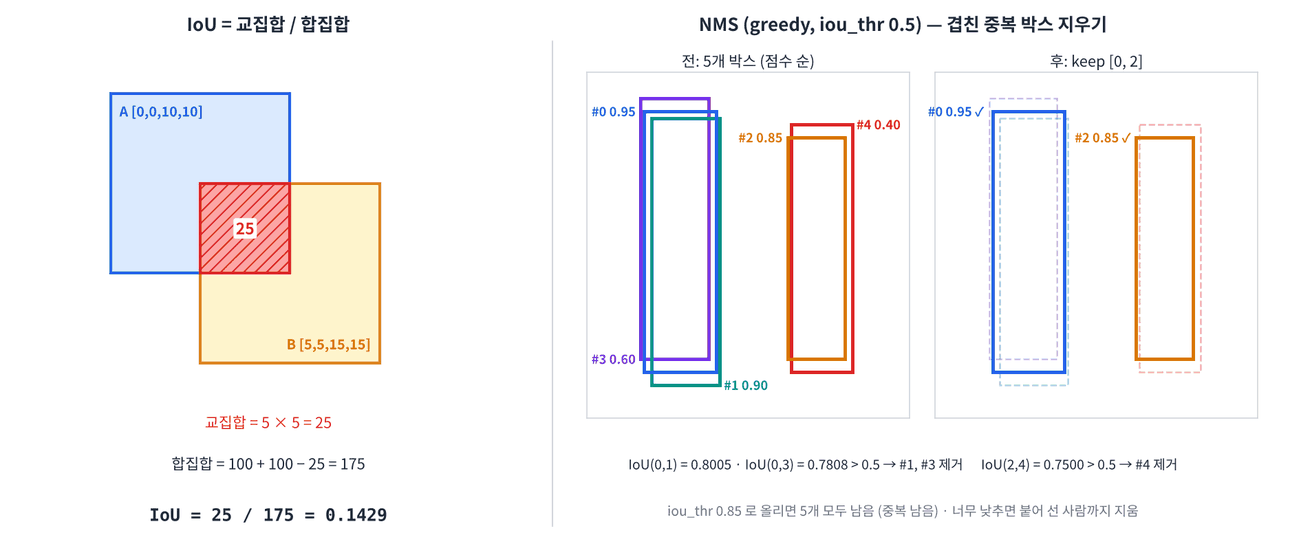

In [ ]:
#@title 🖼 그림 — IoU 계산과 NMS 전후
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f3_iou_nms.png", embed=True, width=860))

**문제 3-1** 박스 하나와 박스 여러 개의 IoU 를 한 번에 구하는 `iou(box, boxes)` 를 완성하세요.

In [ ]:
def iou(box, boxes):
    box = np.asarray(box, float); boxes = np.asarray(boxes, float).reshape(-1, 4)
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.____(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(____, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / (____)

print(iou([0, 0, 10, 10], [[5, 5, 15, 15], [0, 0, 10, 10], [20, 20, 30, 30]]))
print(iou([50, 50, 150, 150], [[60, 60, 160, 160]]))

In [ ]:
assert np.allclose(iou([0, 0, 10, 10], [[5, 5, 15, 15], [0, 0, 10, 10], [20, 20, 30, 30]]), [25 / 175, 1, 0])
assert np.isclose(iou([50, 50, 150, 150], [[60, 60, 160, 160]])[0], 8100 / 11900); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmRlZiBpb3UoYm94LCBib3hlcyk6CiAgICBib3ggPSBucC5hc2FycmF5"
    "KGJveCwgZmxvYXQpOyBib3hlcyA9IG5wLmFzYXJyYXkoYm94ZXMsIGZsb2F0KS5yZXNoYXBlKC0xLCA0KQogICAg"
    "eDEgPSBucC5tYXhpbXVtKGJveFswXSwgYm94ZXNbOiwgMF0pOyB5MSA9IG5wLm1heGltdW0oYm94WzFdLCBib3hl"
    "c1s6LCAxXSkKICAgIHgyID0gbnAubWluaW11bShib3hbMl0sIGJveGVzWzosIDJdKTsgeTIgPSBucC5taW5pbXVt"
    "KGJveFszXSwgYm94ZXNbOiwgM10pCiAgICBpbnRlciA9IG5wLmNsaXAoeDIgLSB4MSwgMCwgTm9uZSkgKiBucC5j"
    "bGlwKHkyIC0geTEsIDAsIE5vbmUpCiAgICBhcmVhID0gbGFtYmRhIGI6IChiWy4uLiwgMl0gLSBiWy4uLiwgMF0p"
    "ICogKGJbLi4uLCAzXSAtIGJbLi4uLCAxXSkKICAgIHJldHVybiBpbnRlciAvIChhcmVhKGJveCkgKyBhcmVhKGJv"
    "eGVzKSAtIGludGVyKQoKcHJpbnQoaW91KFswLCAwLCAxMCwgMTBdLCBbWzUsIDUsIDE1LCAxNV0sIFswLCAwLCAx"
    "MCwgMTBdLCBbMjAsIDIwLCAzMCwgMzBdXSkpCnByaW50KGlvdShbNTAsIDUwLCAxNTAsIDE1MF0sIFtbNjAsIDYw"
    "LCAxNjAsIDE2MF1dKSkKCvCfkqEg7ZW07ISkClswLDAsMTAsMTBdIHZzIFs1LDUsMTUsMTVdOiDqtZDsp5Htlakg"
    "NcOXNSA9IDI1LCDtlansp5HtlakgMTAwICsgMTAwIOKIkiAyNSA9IDE3NSDihpIgMC4xNDI5LiDrp47snbQg6rK5"
    "7LOQIOuztOydtOuKlCBbNTAsNTAsMTUwLDE1MF0gdnMgWzYwLDYwLDE2MCwxNjBdIOuPhCAwLjY4MDcg4oCUIElv"
    "VSDripQg7IOd6rCB67O064ukIOyXhOqyqe2VqeuLiOuLpC4g67CV7Iqk6rCAIDEwIHB4IOunjCDrsIDroKTrj4Qg"
    "MC43IOyVhOuemOuhnCDrlqjslrTsp5Hri4jri6Qu"
).decode("utf-8"))

**문제 3-2** 박스 N개 × M개의 IoU 표 (N×M) 를 반복문 없이 **브로드캐스팅**으로 구하는 `iou_matrix` 를 완성하고, `torchvision.ops.box_iou` 와 같은지 확인하세요.

In [ ]:
def iou_matrix(A, B):
    A = np.asarray(A, float).reshape(-1, 4); B = np.asarray(B, float).reshape(-1, 4)
    x1 = np.maximum(A[:, None, 0], B[None, :, 0]); y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2]); y2 = np.minimum(____)
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)            # (N, M)
    aA = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1]); aB = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return inter / (aA____ + aB[None, :] - inter)

def rand_boxes(n, seed=0):
    g = np.random.default_rng(seed)
    xy = g.uniform(0, 500, (n, 2)); wh = g.uniform(10, 150, (n, 2))
    return np.concatenate([xy, xy + wh], 1)

A, B = rand_boxes(50, 1), rand_boxes(40, 2)
M_np = iou_matrix(A, B)
M_tv = torchvision.ops.box_iou(torch.tensor(A), torch.tensor(B)).numpy()
print(M_np.shape, "| 최대 차이", np.abs(M_np - M_tv).max())

In [ ]:
assert M_np.shape == (50, 40) and np.allclose(M_np, M_tv, atol=1e-9); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACmRlZiBpb3VfbWF0cml4KEEsIEIpOgogICAgQSA9IG5wLmFzYXJyYXko"
    "QSwgZmxvYXQpLnJlc2hhcGUoLTEsIDQpOyBCID0gbnAuYXNhcnJheShCLCBmbG9hdCkucmVzaGFwZSgtMSwgNCkK"
    "ICAgIHgxID0gbnAubWF4aW11bShBWzosIE5vbmUsIDBdLCBCW05vbmUsIDosIDBdKTsgeTEgPSBucC5tYXhpbXVt"
    "KEFbOiwgTm9uZSwgMV0sIEJbTm9uZSwgOiwgMV0pCiAgICB4MiA9IG5wLm1pbmltdW0oQVs6LCBOb25lLCAyXSwg"
    "QltOb25lLCA6LCAyXSk7IHkyID0gbnAubWluaW11bShBWzosIE5vbmUsIDNdLCBCW05vbmUsIDosIDNdKQogICAg"
    "aW50ZXIgPSBucC5jbGlwKHgyIC0geDEsIDAsIE5vbmUpICogbnAuY2xpcCh5MiAtIHkxLCAwLCBOb25lKSAgICAg"
    "ICAgICAgICMgKE4sIE0pCiAgICBhQSA9IChBWzosIDJdIC0gQVs6LCAwXSkgKiAoQVs6LCAzXSAtIEFbOiwgMV0p"
    "OyBhQiA9IChCWzosIDJdIC0gQls6LCAwXSkgKiAoQls6LCAzXSAtIEJbOiwgMV0pCiAgICByZXR1cm4gaW50ZXIg"
    "LyAoYUFbOiwgTm9uZV0gKyBhQltOb25lLCA6XSAtIGludGVyKQoKZGVmIHJhbmRfYm94ZXMobiwgc2VlZD0wKToK"
    "ICAgIGcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoc2VlZCkKICAgIHh5ID0gZy51bmlmb3JtKDAsIDUwMCwgKG4s"
    "IDIpKTsgd2ggPSBnLnVuaWZvcm0oMTAsIDE1MCwgKG4sIDIpKQogICAgcmV0dXJuIG5wLmNvbmNhdGVuYXRlKFt4"
    "eSwgeHkgKyB3aF0sIDEpCgpBLCBCID0gcmFuZF9ib3hlcyg1MCwgMSksIHJhbmRfYm94ZXMoNDAsIDIpCk1fbnAg"
    "PSBpb3VfbWF0cml4KEEsIEIpCk1fdHYgPSB0b3JjaHZpc2lvbi5vcHMuYm94X2lvdSh0b3JjaC50ZW5zb3IoQSks"
    "IHRvcmNoLnRlbnNvcihCKSkubnVtcHkoKQpwcmludChNX25wLnNoYXBlLCAifCDstZzrjIAg7LCo7J20IiwgbnAu"
    "YWJzKE1fbnAgLSBNX3R2KS5tYXgoKSkKCvCfkqEg7ZW07ISkCmBBWzosIE5vbmUsIDBdYCDripQgKE4sIDEpLCBg"
    "QltOb25lLCA6LCAwXWAg64qUICgxLCBNKSDihpIg7Jew7IKw7ZWY66m0IChOLCBNKS4gTnVtUHkg67iM66Gc65Oc"
    "7LqQ7Iqk7YyF7J2AIE5OIOqzvOyglSBpbTJjb2wg65WM7JmAIOqwmeydgCDsm5DrpqzsnoXri4jri6QuIO2Pieqw"
    "gCAoNOq1kOyLnCkg7JeQ7IScICftg5Dsp4Agw5cg7KCV64u1JyBJb1Ug7ZGc6rCAIO2VhOyalO2VoCDrlYwg7JSB"
    "64uI64ukLg=="
).decode("utf-8"))

### NMS (Non-Maximum Suppression)

탐지기는 한 사람 주변에 **비슷한 박스를 여러 개** 냅니다 (sliding window 에서 겹치는 창들이 모두 '사람' 이라고 하는 것과 같습니다). NMS 는 그중 하나만 남깁니다.

1. 점수 높은 순으로 정렬
2. 가장 높은 박스를 **남기고 (keep)**
3. 그 박스와 IoU > `iou_thr` 인 박스를 **지운다**
4. 남은 박스로 2 부터 반복

In [ ]:
# NMS 예제 — 사람 2명에 박스 5개
toy_boxes = np.array([[100, 100, 200, 300], [110, 105, 205, 310], [300, 120, 380, 290],
                      [95, 90, 190, 290], [305, 110, 390, 300]], float)
toy_scores = np.array([0.95, 0.90, 0.85, 0.60, 0.40])
print("IoU(0, 1..4):", iou(toy_boxes[0], toy_boxes[1:]).round(4), "| IoU(2, 4):", iou(toy_boxes[2], toy_boxes[4:]).round(4))

**문제 3-3** greedy NMS 를 완성하세요. 남긴 박스의 **인덱스** 를 점수 순으로 돌려줍니다. 위 예제에서 `[0, 2]` 가 나오고, 무작위 박스 300개에서 `torchvision.ops.nms` 와 같은 결과가 나와야 합니다.

In [ ]:
def nms(boxes, scores, iou_thr=0.5):
    boxes = np.asarray(boxes, float); scores = np.asarray(scores, float)
    order = np.argsort(____)                 # 점수 높은 순
    keep = []
    while order.size > 0:
        i = order[0]
        keep.append(____)
        rest = order[1:]
        order = rest[iou(boxes[i], boxes[rest]) ____ iou_thr]      # 많이 겹치는 박스는 지운다
    return np.array(keep, dtype=int)

print("toy:", nms(toy_boxes, toy_scores, 0.5))
Bx = rand_boxes(300, 3); Sx = np.random.default_rng(4).random(300)
k_np = nms(Bx, Sx, 0.5)
k_tv = torchvision.ops.nms(torch.tensor(Bx), torch.tensor(Sx), 0.5).numpy()
print("무작위 300개 →", len(k_np), "개 남김 | torchvision 과 같음:", np.array_equal(k_np, k_tv))

In [ ]:
assert nms(toy_boxes, toy_scores, 0.5).tolist() == [0, 2] and len(nms(toy_boxes, toy_scores, 0.85)) == 5
assert np.array_equal(k_np, k_tv); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACmRlZiBubXMoYm94ZXMsIHNjb3JlcywgaW91X3Rocj0wLjUpOgogICAg"
    "Ym94ZXMgPSBucC5hc2FycmF5KGJveGVzLCBmbG9hdCk7IHNjb3JlcyA9IG5wLmFzYXJyYXkoc2NvcmVzLCBmbG9h"
    "dCkKICAgIG9yZGVyID0gbnAuYXJnc29ydCgtc2NvcmVzKSAgICAgICAgICAgICAgICAgIyDsoJDsiJgg64aS7J2A"
    "IOyInAogICAga2VlcCA9IFtdCiAgICB3aGlsZSBvcmRlci5zaXplID4gMDoKICAgICAgICBpID0gb3JkZXJbMF0K"
    "ICAgICAgICBrZWVwLmFwcGVuZChpKQogICAgICAgIHJlc3QgPSBvcmRlclsxOl0KICAgICAgICBvcmRlciA9IHJl"
    "c3RbaW91KGJveGVzW2ldLCBib3hlc1tyZXN0XSkgPD0gaW91X3Rocl0gICAgICAjIOunjuydtCDqsrnsuZjripQg"
    "67CV7Iqk64qUIOyngOyatOuLpAogICAgcmV0dXJuIG5wLmFycmF5KGtlZXAsIGR0eXBlPWludCkKCnByaW50KCJ0"
    "b3k6Iiwgbm1zKHRveV9ib3hlcywgdG95X3Njb3JlcywgMC41KSkKQnggPSByYW5kX2JveGVzKDMwMCwgMyk7IFN4"
    "ID0gbnAucmFuZG9tLmRlZmF1bHRfcm5nKDQpLnJhbmRvbSgzMDApCmtfbnAgPSBubXMoQngsIFN4LCAwLjUpCmtf"
    "dHYgPSB0b3JjaHZpc2lvbi5vcHMubm1zKHRvcmNoLnRlbnNvcihCeCksIHRvcmNoLnRlbnNvcihTeCksIDAuNSku"
    "bnVtcHkoKQpwcmludCgi66y07J6R7JyEIDMwMOqwnCDihpIiLCBsZW4oa19ucCksICLqsJwg64Ko6rmAIHwgdG9y"
    "Y2h2aXNpb24g6rO8IOqwmeydjDoiLCBucC5hcnJheV9lcXVhbChrX25wLCBrX3R2KSkKCvCfkqEg7ZW07ISkCklv"
    "VSgwLDEpID0gMC44MDA1LCBJb1UoMCwzKSA9IDAuNzgwOCDihpIgMCDsnbQg64Ko6rOgIDEgwrcgMyDsnbQg7KeA"
    "7JuM7KeQLiDri6TsnYzsnLzroZwg64aS7J2AIDIg6rCAIOuCqOqzoCBJb1UoMiw0KSA9IDAuNzUg4oaSIDQg6rCA"
    "IOyngOybjOynkC4g6rKw6rO8IFswLCAyXS4g6riw7KSA7J2EIDAuODUg66GcIOyYrOumrOuptCDslYTrrLTqsoPr"
    "j4Qg7KeA7JuM7KeA7KeAIOyViuyVhCA16rCc6rCAIOuLpCDrgqjsirXri4jri6QgKOykkeuztSDrsJXsiqQpLgp0"
    "b3JjaHZpc2lvbi5vcHMubm1zIOuPhCAnSW9VID4g6riw7KSA7J2066m0IOygnOqxsCcg65287IScIGA8PWAg7J24"
    "IOuwleyKpOulvCDrgqjquLDrqbQg6rCZ7J2AIOqysOqzvOyeheuLiOuLpC4g7Iuk7KCcIOudvOydtOu4jOufrOum"
    "rOuKlCDqsJnsnYAg7J287J2EIEMrKy9DVURBIOuhnCDruaDrpbTqsowg7ZWp64uI64ukLg=="
).decode("utf-8"))

### 두 개의 threshold

| threshold | 하는 일 | 너무 낮으면 | 너무 높으면 |
|---|---|---|---|
| **conf (점수)** | 점수 낮은 박스를 NMS 전에 버린다 | 오탐 (FP) 이 많다 | 사람을 놓친다 (FN) |
| **IoU (NMS)** | 이만큼 겹치면 같은 물체로 본다 | 붙어 선 두 사람 중 하나를 지운다 | 한 사람에 박스가 여러 개 남는다 |

In [ ]:
# 가짜 탐지기: 정답 박스 주변에 흔들린 박스 15개씩 + 배경에 낮은 점수 박스 10개 (사람이 가장 많은 이미지)
def fake_detector(g, W, H, n_per=15, n_bg=10, seed=0):
    rs = np.random.default_rng(seed); B, S = [], []
    for b in g:
        w, h = b[2] - b[0], b[3] - b[1]
        for _ in range(n_per):
            jit = rs.normal(0, 0.08, 4) * [w, h, w, h]
            B.append(b + jit); S.append(np.clip(0.9 - np.abs(jit).sum() / (w + h) + rs.normal(0, 0.05), 0.05, 0.99))
    for _ in range(n_bg):
        x, y = rs.uniform(0, W - 60), rs.uniform(0, H - 120)
        B.append([x, y, x + rs.uniform(30, 60), y + rs.uniform(60, 120)]); S.append(rs.uniform(0.05, 0.45))
    return np.array(B), np.array(S)

ib = int(idx4[0]); img_b = load_rgb(img_paths[ib]); Hb, Wb = img_b.shape[:2]
fake_B, fake_S = fake_detector(gts[ib], Wb, Hb)
print(f"{os.path.basename(img_paths[ib])}: 정답 {len(gts[ib])}명, 가짜 탐지 {len(fake_B)}개")

**문제 3-4** conf 기준 (0.3, 0.5) × IoU 기준 (0.3, 0.5, 0.7) 에서 NMS 후 남는 박스 수를 표로 만드세요. 정답 인원과 비교합니다.

In [ ]:
table = {}
for conf_thr in (0.3, 0.5):
    for iou_thr in (0.3, 0.5, 0.7):
        m = fake_S >= ____
        keep = nms(fake_B[m], fake_S[m], ____)
        table[(conf_thr, iou_thr)] = len(keep)
print("정답", len(gts[ib]), "명")
for (c, t), n in table.items():
    print(f"conf ≥ {c}  IoU 기준 {t}  →  {n:3d} 개")
m = fake_S >= 0.5; keep = nms(fake_B[m], fake_S[m], 0.5)
show([draw_boxes(img_b, fake_B, (255, 80, 80), thick=1), draw_boxes(img_b, fake_B[m][keep])],
     [f"before NMS: {len(fake_B)} boxes", f"conf 0.5 + NMS 0.5: {len(keep)} boxes"], cols=2, size=4.5)

In [ ]:
assert len(table) == 6 and all(table[(c, 0.3)] <= table[(c, 0.5)] <= table[(c, 0.7)] for c in (0.3, 0.5))
assert all(table[(0.5, t)] <= table[(0.3, t)] for t in (0.3, 0.5, 0.7)); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTQg4pSA4pSACnRhYmxlID0ge30KZm9yIGNvbmZfdGhyIGluICgwLjMsIDAuNSk6CiAg"
    "ICBmb3IgaW91X3RociBpbiAoMC4zLCAwLjUsIDAuNyk6CiAgICAgICAgbSA9IGZha2VfUyA+PSBjb25mX3Rocgog"
    "ICAgICAgIGtlZXAgPSBubXMoZmFrZV9CW21dLCBmYWtlX1NbbV0sIGlvdV90aHIpCiAgICAgICAgdGFibGVbKGNv"
    "bmZfdGhyLCBpb3VfdGhyKV0gPSBsZW4oa2VlcCkKcHJpbnQoIuygleuLtSIsIGxlbihndHNbaWJdKSwgIuuqhSIp"
    "CmZvciAoYywgdCksIG4gaW4gdGFibGUuaXRlbXMoKToKICAgIHByaW50KGYiY29uZiDiiaUge2N9ICBJb1Ug6riw"
    "7KSAIHt0fSAg4oaSICB7bjozZH0g6rCcIikKbSA9IGZha2VfUyA+PSAwLjU7IGtlZXAgPSBubXMoZmFrZV9CW21d"
    "LCBmYWtlX1NbbV0sIDAuNSkKc2hvdyhbZHJhd19ib3hlcyhpbWdfYiwgZmFrZV9CLCAoMjU1LCA4MCwgODApLCB0"
    "aGljaz0xKSwgZHJhd19ib3hlcyhpbWdfYiwgZmFrZV9CW21dW2tlZXBdKV0sCiAgICAgW2YiYmVmb3JlIE5NUzog"
    "e2xlbihmYWtlX0IpfSBib3hlcyIsIGYiY29uZiAwLjUgKyBOTVMgMC41OiB7bGVuKGtlZXApfSBib3hlcyJdLCBj"
    "b2xzPTIsIHNpemU9NC41KQoK8J+SoSDtlbTshKQKSW9VIOq4sOykgOydtCDrhpLsnYTsiJjroZ0gKOuNnCDqsrns"
    "s5Drj4Qg64uk66W4IOusvOyytOuhnCDrtIQpIOuwleyKpOqwgCDrp47snbQg64Ko6rOgLCBjb25mIOq4sOykgOyd"
    "tCDrhpLsnYTsiJjroZ0g7KCB6rKMIOuCqOyKteuLiOuLpCDigJQg7ZmV7J24IOyFgOydtCDsnbQg65GQIOuwqe2W"
    "peydhCDqsoDsgqztlanri4jri6QuIOyCrOuejOuTpOydtCDrtpnslrQg7IScIOyeiOuKlCDsgqzsp4Tsl5DshJwg"
    "SW9VIOq4sOykgCAwLjMg7J2AIOyYhiDsgqzrnowg67CV7Iqk6rmM7KeAIOyngOyauCDsiJgg7J6I7Iq164uI64uk"
    "LiDrs7TthrUg7YOQ7KeA6riw7J2YIOq4sOuzuOqwkuydgCBjb25mIDAuMjUgwrcgSW9VIDAuNDV+MC43IOq3vOyy"
    "mOydtOqzoCwg7ZiE7J6l7JeQIOunnuqyjCDsobDsoJXtlanri4jri6QgKDjqtZDsi5wg6rO87KCcIDMpLg=="
).decode("utf-8"))

#### 📌 3교시 정리

- IoU = 교집합 / 합집합. 10 px 밀려도 크게 떨어지는 엄격한 지표.
- NMS = 점수 순으로 하나 남기고 많이 겹친 것 지우기 반복. 직접 만든 코드 = torchvision.ops.nms.
- conf 기준 (오탐 ↔ 놓침) 과 IoU 기준 (중복 ↔ 붙은 물체 삭제) 은 다른 손잡이다.

## 4교시 — 평가 지표: Precision · Recall · AP · mAP

탐지 하나하나를 정답과 비교해 판정합니다.

- **TP** (맞음): 같은 클래스 정답과 IoU ≥ 0.5 — 단, 한 정답에는 **처음 매칭된 탐지 하나만** TP
- **FP** (오탐): 맞는 정답이 없거나, 이미 다른 탐지가 차지한 정답에 또 매칭된 중복
- **FN** (놓침): 어떤 탐지도 매칭되지 않은 정답

$$\text{Precision} = \frac{TP}{TP + FP} \;(\text{찾은 것 중 맞은 비율}), \qquad \text{Recall} = \frac{TP}{\text{정답 수}} \;(\text{정답 중 찾은 비율})$$

conf 기준을 바꿀 때마다 P · R 이 바뀌므로, 기준 하나가 아니라 **모든 기준** 에서의 성능을 한 숫자로 요약한 것이 **AP** (PR 곡선 아래 넓이) 입니다.

**AP 계산 순서**: 모든 이미지의 탐지를 점수 높은 순으로 정렬 → 위에서부터 TP/FP 판정 → 누적 TP · FP → P · R → precision 을 오른쪽부터 최댓값으로 채운 **envelope** → 넓이.

> 🎬 **애니메이션** [D4-4 PR 곡선과 AP](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 손 계산 예제

정답 4개, 탐지 5개 (점수 순): TP, TP, FP, TP, FP

| 순위 | 점수 | 판정 | 누적 TP | 누적 FP | Precision | Recall |
|---|---|---|---|---|---|---|
| 1 | 0.95 | TP | 1 | 0 | 1.00 | 0.25 |
| 2 | 0.90 | TP | 2 | 0 | 1.00 | 0.50 |
| 3 | 0.80 | FP | 2 | 1 | 0.67 | 0.50 |
| 4 | 0.60 | TP | 3 | 1 | 0.75 | 0.75 |
| 5 | 0.50 | FP | 3 | 2 | 0.60 | 0.75 |

envelope: Recall 0~0.5 구간 precision 1, 0.5~0.75 구간 0.75, 0.75~1 구간 0 (더 못 찾음) → **AP = 0.25×1 + 0.25×1 + 0.25×0.75 = 0.6875**

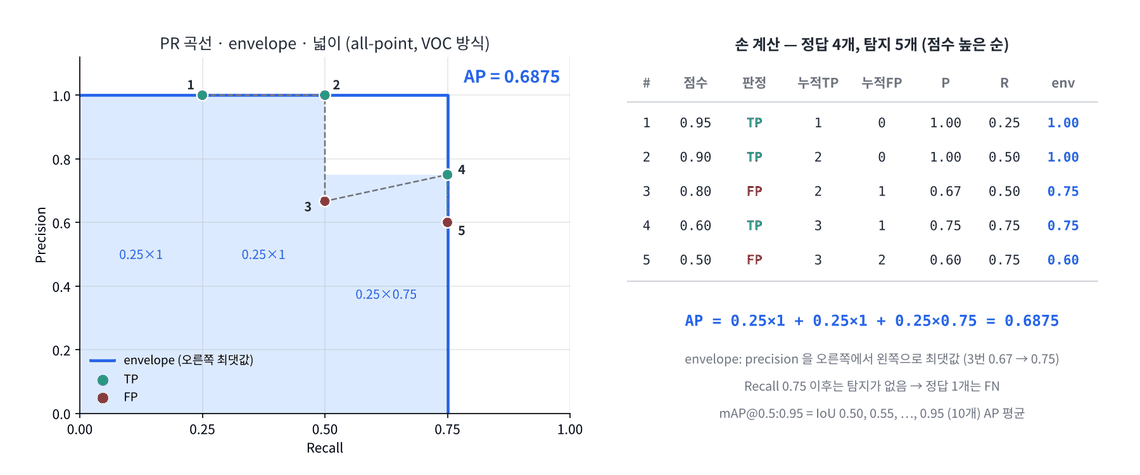

In [ ]:
#@title 🖼 그림 — PR 곡선 · envelope · AP 넓이
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f4_pr_ap.png", embed=True, width=760))

In [ ]:
toy_tp = np.array([1, 1, 0, 1, 0]); toy_n_gt = 4

**문제 4-1** 점수 순으로 정렬된 TP(1)/FP(0) 배열과 정답 수로 누적 Precision · Recall 을 구하는 `precision_recall` 을 완성하세요.

In [ ]:
def precision_recall(tp, n_gt):
    tp = np.asarray(tp, float)
    ctp = np.cumsum(tp); cfp = np.cumsum(____)
    precision = ctp / np.maximum(ctp + cfp, 1e-12)
    recall = ctp / max(____, 1)
    return precision, recall

P_toy, R_toy = precision_recall(toy_tp, toy_n_gt)
print("P", P_toy.round(4), "\nR", R_toy)

In [ ]:
assert np.allclose(P_toy, [1, 1, 2 / 3, 0.75, 0.6]) and np.allclose(R_toy, [0.25, 0.5, 0.5, 0.75, 0.75]); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmRlZiBwcmVjaXNpb25fcmVjYWxsKHRwLCBuX2d0KToKICAgIHRwID0g"
    "bnAuYXNhcnJheSh0cCwgZmxvYXQpCiAgICBjdHAgPSBucC5jdW1zdW0odHApOyBjZnAgPSBucC5jdW1zdW0oMSAt"
    "IHRwKQogICAgcHJlY2lzaW9uID0gY3RwIC8gbnAubWF4aW11bShjdHAgKyBjZnAsIDFlLTEyKQogICAgcmVjYWxs"
    "ID0gY3RwIC8gbWF4KG5fZ3QsIDEpCiAgICByZXR1cm4gcHJlY2lzaW9uLCByZWNhbGwKClBfdG95LCBSX3RveSA9"
    "IHByZWNpc2lvbl9yZWNhbGwodG95X3RwLCB0b3lfbl9ndCkKcHJpbnQoIlAiLCBQX3RveS5yb3VuZCg0KSwgIlxu"
    "UiIsIFJfdG95KQ=="
).decode("utf-8"))

**문제 4-2** P · R 로 AP 를 구하는 `ap_from_pr` 을 완성하세요 (all-point 보간, Pascal VOC 방식). 양 끝에 (R=0) · (R=1, P=0) 을 붙이고, precision 을 **뒤에서 앞으로** 최댓값으로 바꾼 뒤 recall 이 바뀌는 구간의 넓이를 더합니다.

In [ ]:
def ap_from_pr(rec, prec):
    mrec = np.concatenate([[0.0], rec, [1.0]])
    mpre = np.concatenate([[0.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1):              # envelope: 오른쪽 최댓값으로 채우기
        mpre[i] = max(mpre[i], ____)
    idx = np.where(mrec[1:] != mrec[:-1])[0]             # recall 이 바뀌는 지점
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * ____))

ap_toy = ap_from_pr(R_toy, P_toy)
print("AP =", ap_toy)
plt.figure(figsize=(4.5, 3.5))
plt.plot(R_toy, P_toy, "o--", label="P, R points")
env = np.maximum.accumulate(np.concatenate([P_toy, [0]])[::-1])[::-1][:-1]
plt.step(np.concatenate([[0], R_toy]), np.concatenate([[env[0]], env]), where="pre", label="envelope")
plt.xlim(0, 1.02); plt.ylim(0, 1.05); plt.xlabel("recall"); plt.ylabel("precision"); plt.legend(); plt.title(f"AP = {ap_toy:.4f}"); plt.show()

In [ ]:
assert np.isclose(ap_toy, 0.6875) and ap_from_pr(np.array([]), np.array([])) == 0.0; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiBhcF9mcm9tX3ByKHJlYywgcHJlYyk6CiAgICBtcmVjID0gbnAu"
    "Y29uY2F0ZW5hdGUoW1swLjBdLCByZWMsIFsxLjBdXSkKICAgIG1wcmUgPSBucC5jb25jYXRlbmF0ZShbWzAuMF0s"
    "IHByZWMsIFswLjBdXSkKICAgIGZvciBpIGluIHJhbmdlKGxlbihtcHJlKSAtIDIsIC0xLCAtMSk6ICAgICAgICAg"
    "ICAgICAjIGVudmVsb3BlOiDsmKTrpbjsqr0g7LWc64yT6rCS7Jy866GcIOyxhOyasOq4sAogICAgICAgIG1wcmVb"
    "aV0gPSBtYXgobXByZVtpXSwgbXByZVtpICsgMV0pCiAgICBpZHggPSBucC53aGVyZShtcmVjWzE6XSAhPSBtcmVj"
    "WzotMV0pWzBdICAgICAgICAgICAgICMgcmVjYWxsIOydtCDrsJTrgIzripQg7KeA7KCQCiAgICByZXR1cm4gZmxv"
    "YXQobnAuc3VtKChtcmVjW2lkeCArIDFdIC0gbXJlY1tpZHhdKSAqIG1wcmVbaWR4ICsgMV0pKQoKYXBfdG95ID0g"
    "YXBfZnJvbV9wcihSX3RveSwgUF90b3kpCnByaW50KCJBUCA9IiwgYXBfdG95KQpwbHQuZmlndXJlKGZpZ3NpemU9"
    "KDQuNSwgMy41KSkKcGx0LnBsb3QoUl90b3ksIFBfdG95LCAiby0tIiwgbGFiZWw9IlAsIFIgcG9pbnRzIikKZW52"
    "ID0gbnAubWF4aW11bS5hY2N1bXVsYXRlKG5wLmNvbmNhdGVuYXRlKFtQX3RveSwgWzBdXSlbOjotMV0pWzo6LTFd"
    "WzotMV0KcGx0LnN0ZXAobnAuY29uY2F0ZW5hdGUoW1swXSwgUl90b3ldKSwgbnAuY29uY2F0ZW5hdGUoW1tlbnZb"
    "MF1dLCBlbnZdKSwgd2hlcmU9InByZSIsIGxhYmVsPSJlbnZlbG9wZSIpCnBsdC54bGltKDAsIDEuMDIpOyBwbHQu"
    "eWxpbSgwLCAxLjA1KTsgcGx0LnhsYWJlbCgicmVjYWxsIik7IHBsdC55bGFiZWwoInByZWNpc2lvbiIpOyBwbHQu"
    "bGVnZW5kKCk7IHBsdC50aXRsZShmIkFQID0ge2FwX3RveTouNGZ9Iik7IHBsdC5zaG93KCkKCvCfkqEg7ZW07ISk"
    "CmVudmVsb3BlIOuKlCAn7J20IHJlY2FsbCDsnbTsg4Hsl5DshJwg7Ja77J2EIOyImCDsnojripQg7LWc6rOgIHBy"
    "ZWNpc2lvbicg7J6F64uI64ukLiAz7JyEIEZQIOuhnCDsnqDquZAgMC42NyDroZwg65ao7Ja07KeEIHByZWNpc2lv"
    "biDrj4Qg65Kk7J2YIDAuNzUg66GcIOyxhOybjOynkeuLiOuLpC4gQ09DTyAocHljb2NvdG9vbHMpIOyZgCB1bHRy"
    "YWx5dGljcyDripQgcmVjYWxsIDAsIDAuMDEsIOKApiwgMSDsnZggKioxMDHsoJAg67O06rCEKirsnYQg7I2o7ISc"
    "IOqwkuydtCDsobDquIgg64uk66W8IOyImCDsnojsirXri4jri6Qg4oCUIOu5hOq1kO2VoCDrlYzripQg6rCZ7J2A"
    "IOuwqeyLneuBvOumrC4="
).decode("utf-8"))

**문제 4-3** 여러 이미지의 탐지를 정답과 매칭하는 `match_detections` 를 완성하세요.

- `dets[i]` = i번 이미지의 탐지 (K, 5) = [x1, y1, x2, y2, score], `gts[i]` = 정답 (G, 4)
- 모든 이미지의 탐지를 점수 순으로 정렬 → 각 탐지를 같은 이미지에서 IoU 가 가장 큰 정답과 비교 → IoU ≥ 기준이고 **아직 안 쓴 정답**이면 TP

In [ ]:
def match_detections(dets, gts, iou_thr=0.5):
    recs = []
    for i, d in enumerate(dets):
        for row in np.asarray(d, float).reshape(-1, 5):
            recs.append((row[4], i, row[:4]))
    recs.sort(key=lambda t: -t[0])                       # 모든 이미지의 탐지를 점수 순으로
    used = [np.zeros(len(g), bool) for g in gts]
    scores, tp = [], []
    for s, i, b in recs:
        ok = 0
        if len(gts[i]):
            o = iou(b, gts[i]); j = int(o.argmax())
            if o[j] >= ____ and not ____:
                used[i][j] = True; ok = 1
        scores.append(s); tp.append(ok)
    return np.array(scores), np.array(tp), sum(len(g) for g in gts)

mini_gts = [np.array([[0, 0, 10, 10], [20, 20, 30, 30]], float), np.array([[0, 0, 10, 10]], float)]
mini_dets = [np.array([[0, 0, 10, 10, 0.9], [1, 1, 10, 10, 0.8], [50, 50, 60, 60, 0.7]]), np.array([[0, 0, 9, 10, 0.6]])]
print(match_detections(mini_dets, mini_gts))

In [ ]:
s_, tp_, n_ = match_detections(mini_dets, mini_gts)
assert tp_.tolist() == [1, 0, 0, 1] and n_ == 3 and np.allclose(s_, [0.9, 0.8, 0.7, 0.6]); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACmRlZiBtYXRjaF9kZXRlY3Rpb25zKGRldHMsIGd0cywgaW91X3Rocj0w"
    "LjUpOgogICAgcmVjcyA9IFtdCiAgICBmb3IgaSwgZCBpbiBlbnVtZXJhdGUoZGV0cyk6CiAgICAgICAgZm9yIHJv"
    "dyBpbiBucC5hc2FycmF5KGQsIGZsb2F0KS5yZXNoYXBlKC0xLCA1KToKICAgICAgICAgICAgcmVjcy5hcHBlbmQo"
    "KHJvd1s0XSwgaSwgcm93Wzo0XSkpCiAgICByZWNzLnNvcnQoa2V5PWxhbWJkYSB0OiAtdFswXSkgICAgICAgICAg"
    "ICAgICAgICAgICAgICMg66qo65OgIOydtOuvuOyngOydmCDtg5Dsp4Drpbwg7KCQ7IiYIOyInOycvOuhnAogICAg"
    "dXNlZCA9IFtucC56ZXJvcyhsZW4oZyksIGJvb2wpIGZvciBnIGluIGd0c10KICAgIHNjb3JlcywgdHAgPSBbXSwg"
    "W10KICAgIGZvciBzLCBpLCBiIGluIHJlY3M6CiAgICAgICAgb2sgPSAwCiAgICAgICAgaWYgbGVuKGd0c1tpXSk6"
    "CiAgICAgICAgICAgIG8gPSBpb3UoYiwgZ3RzW2ldKTsgaiA9IGludChvLmFyZ21heCgpKQogICAgICAgICAgICBp"
    "ZiBvW2pdID49IGlvdV90aHIgYW5kIG5vdCB1c2VkW2ldW2pdOgogICAgICAgICAgICAgICAgdXNlZFtpXVtqXSA9"
    "IFRydWU7IG9rID0gMQogICAgICAgIHNjb3Jlcy5hcHBlbmQocyk7IHRwLmFwcGVuZChvaykKICAgIHJldHVybiBu"
    "cC5hcnJheShzY29yZXMpLCBucC5hcnJheSh0cCksIHN1bShsZW4oZykgZm9yIGcgaW4gZ3RzKQoKbWluaV9ndHMg"
    "PSBbbnAuYXJyYXkoW1swLCAwLCAxMCwgMTBdLCBbMjAsIDIwLCAzMCwgMzBdXSwgZmxvYXQpLCBucC5hcnJheShb"
    "WzAsIDAsIDEwLCAxMF1dLCBmbG9hdCldCm1pbmlfZGV0cyA9IFtucC5hcnJheShbWzAsIDAsIDEwLCAxMCwgMC45"
    "XSwgWzEsIDEsIDEwLCAxMCwgMC44XSwgWzUwLCA1MCwgNjAsIDYwLCAwLjddXSksIG5wLmFycmF5KFtbMCwgMCwg"
    "OSwgMTAsIDAuNl1dKV0KcHJpbnQobWF0Y2hfZGV0ZWN0aW9ucyhtaW5pX2RldHMsIG1pbmlfZ3RzKSkKCvCfkqEg"
    "7ZW07ISkCjAuOSDihpIg7LKrIOydtOuvuOyngCDsoJXri7UgMCDqs7wgSW9VIDEg4oaSIFRQLiAwLjgg4oaSIOqw"
    "meydgCDsoJXri7Xqs7wgSW9VIDAuODEg7J207KeA66eMIOydtOuvuCDsgqzsmqnrkKgg4oaSICoq7KSR67O1IEZQ"
    "KiouIDAuNyDihpIg6rK57LmY64qUIOygleuLtSDsl4bsnYwg4oaSIEZQLiAwLjYg4oaSIOuRmOynuCDsnbTrr7js"
    "p4Ag7KCV64u16rO8IElvVSAwLjkg4oaSIFRQLiDssqsg7J2066+47KeA7J2YIFsyMCwyMCwzMCwzMF0g7J2AIOuB"
    "neq5jOyngCDrp6Tsua0g7JWIIOuQqCDihpIgRk4gKHJlY2FsbCDsnZgg67aE66qo7JeQ66eMIOuTpOyWtOqwkCku"
    "IE5NUyDqsIAg7KSR67O17J2EIOygnOuMgOuhnCDrqrsg7KeA7Jqw66m0IOydtOugh+qyjCBwcmVjaXNpb24g7J20"
    "IOuWqOyWtOynkeuLiOuLpC4="
).decode("utf-8"))

**문제 4-4** 위 함수들을 엮어 `evaluate_ap` (IoU 기준 하나) 와 `map_50_95` (IoU 0.50, 0.55, …, 0.95 의 평균 — COCO 주 지표) 를 완성하세요. 확인용으로 '완벽한 탐지기' 와 '박스를 폭의 10% 만큼 옆으로 민 탐지기' 를 평가합니다.

In [ ]:
def evaluate_ap(dets, gts, iou_thr=0.5):
    scores, tp, n_gt = match_detections(dets, gts, iou_thr)
    precision, recall = ____
    return ap_from_pr(recall, precision)

IOU_THRS = np.arange(0.5, 0.96, 0.05)                    # 0.50, 0.55, ..., 0.95 (10개)
def map_50_95(dets, gts):
    return float(np.mean([evaluate_ap(dets, gts, t) for t in ____]))

perfect = [np.concatenate([g, np.ones((len(g), 1))], 1) for g in gts]
def shift(g, frac=0.1):
    w = (g[:, 2] - g[:, 0])[:, None]
    return np.concatenate([g + frac * w * np.array([1, 0, 1, 0]), np.ones((len(g), 1))], 1)
shifted = [shift(g) for g in gts]
print(f"완벽한 탐지기   AP50 {evaluate_ap(perfect, gts):.4f}  mAP50-95 {map_50_95(perfect, gts):.4f}")
print(f"10% 밀린 탐지기 AP50 {evaluate_ap(shifted, gts):.4f}  mAP50-95 {map_50_95(shifted, gts):.4f}")

In [ ]:
assert len(IOU_THRS) == 10 and np.isclose(evaluate_ap(perfect, gts), 1) and np.isclose(map_50_95(perfect, gts), 1)
assert np.isclose(evaluate_ap(shifted, gts), 1) and np.isclose(map_50_95(shifted, gts), 0.7); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTQg4pSA4pSACmRlZiBldmFsdWF0ZV9hcChkZXRzLCBndHMsIGlvdV90aHI9MC41KToK"
    "ICAgIHNjb3JlcywgdHAsIG5fZ3QgPSBtYXRjaF9kZXRlY3Rpb25zKGRldHMsIGd0cywgaW91X3RocikKICAgIHBy"
    "ZWNpc2lvbiwgcmVjYWxsID0gcHJlY2lzaW9uX3JlY2FsbCh0cCwgbl9ndCkKICAgIHJldHVybiBhcF9mcm9tX3By"
    "KHJlY2FsbCwgcHJlY2lzaW9uKQoKSU9VX1RIUlMgPSBucC5hcmFuZ2UoMC41LCAwLjk2LCAwLjA1KSAgICAgICAg"
    "ICAgICAgICAgICAgIyAwLjUwLCAwLjU1LCAuLi4sIDAuOTUgKDEw6rCcKQpkZWYgbWFwXzUwXzk1KGRldHMsIGd0"
    "cyk6CiAgICByZXR1cm4gZmxvYXQobnAubWVhbihbZXZhbHVhdGVfYXAoZGV0cywgZ3RzLCB0KSBmb3IgdCBpbiBJ"
    "T1VfVEhSU10pKQoKcGVyZmVjdCA9IFtucC5jb25jYXRlbmF0ZShbZywgbnAub25lcygobGVuKGcpLCAxKSldLCAx"
    "KSBmb3IgZyBpbiBndHNdCmRlZiBzaGlmdChnLCBmcmFjPTAuMSk6CiAgICB3ID0gKGdbOiwgMl0gLSBnWzosIDBd"
    "KVs6LCBOb25lXQogICAgcmV0dXJuIG5wLmNvbmNhdGVuYXRlKFtnICsgZnJhYyAqIHcgKiBucC5hcnJheShbMSwg"
    "MCwgMSwgMF0pLCBucC5vbmVzKChsZW4oZyksIDEpKV0sIDEpCnNoaWZ0ZWQgPSBbc2hpZnQoZykgZm9yIGcgaW4g"
    "Z3RzXQpwcmludChmIuyZhOuyve2VnCDtg5Dsp4DquLAgICBBUDUwIHtldmFsdWF0ZV9hcChwZXJmZWN0LCBndHMp"
    "Oi40Zn0gIG1BUDUwLTk1IHttYXBfNTBfOTUocGVyZmVjdCwgZ3RzKTouNGZ9IikKcHJpbnQoZiIxMCUg67CA66aw"
    "IO2DkOyngOq4sCBBUDUwIHtldmFsdWF0ZV9hcChzaGlmdGVkLCBndHMpOi40Zn0gIG1BUDUwLTk1IHttYXBfNTBf"
    "OTUoc2hpZnRlZCwgZ3RzKTouNGZ9IikKCvCfkqEg7ZW07ISkCu2PreydmCAxMCUg66eM7YG8IOuwgOuptCBJb1Ug"
    "PSAwLjkvMS4xID0gMC44MTgg4oaSIElvVSDquLDspIAgMC41fjAuOCAoN+qwnCkg7JeQ7ISc64qUIOuqqOuRkCBU"
    "UCwgMC44NSDCtyAwLjkgwrcgMC45NSAoM+qwnCkg7JeQ7ISc64qUIOuqqOuRkCBGUCDihpIgbUFQNTAtOTUgPSA3"
    "LzEwID0gMC43LiBBUDUwIOydgCAxIOq3uOuMgOuhnOyeheuLiOuLpC4gKipBUDUwIOydgCAn7LC+7JWY64KYJywg"
    "bUFQNTAtOTUg64qUICfslrzrp4jrgpgg7KCV7ZmV7ZWcIOychOy5mOyXkCcqKiDquYzsp4Ag67SF64uI64ukLiDt"
    "gbTrnpjsiqTqsIAg7Jes65+sIOqwnOuptCDtgbTrnpjsiqTrp4jri6QgQVAg66W8IOuCtOyEnCDtj4nqt6AgKD0g"
    "bUFQKSDtlanri4jri6QuIOyYpOuKmOydgCBwZXJzb24g7ZWY64KY6528IG1BUCA9IEFQLg=="
).decode("utf-8"))

### 내 평가 코드를 파일로 — `iou_nms_map.py`

오늘 만든 함수들을 파일 하나로 저장해 두면 Day 5 와 YOLOv8 Edge 과목에서 `import` 해서 씁니다.

In [ ]:
funcs = [iou, iou_matrix, nms, precision_recall, ap_from_pr, match_detections, evaluate_ap, map_50_95]
src = '"""Vision 기본 모델 Day 4 — IoU · NMS · AP · mAP (NumPy)"""\nimport numpy as np\n\nIOU_THRS = np.arange(0.5, 0.96, 0.05)\n\n\n'
src += "\n\n".join(inspect.getsource(f) for f in funcs)
open("iou_nms_map.py", "w", encoding="utf-8").write(src)
import importlib, iou_nms_map; importlib.reload(iou_nms_map)
assert np.isclose(iou_nms_map.evaluate_ap(shifted, gts), 1.0) and iou_nms_map.nms(toy_boxes, toy_scores).tolist() == [0, 2]
print("✅ iou_nms_map.py 저장 ·", len(src.splitlines()), "줄 — 왼쪽 파일 탭에서 내려받을 수 있습니다")

#### 📌 4교시 정리

- TP = IoU ≥ 기준 + 처음 매칭. 중복은 FP. 못 찾은 정답은 FN.
- AP = 점수 순 누적 P · R 곡선의 envelope 아래 넓이. 손 계산 예 0.6875.
- AP50 = 찾았나, mAP50-95 = 위치까지 정확한가. 10% 밀린 박스: AP50 1.0, mAP50-95 0.7.

## 5교시 — 2-stage vs 1-stage: Faster R-CNN · SSD

### Anchor — 미리 깔아 둔 기준 박스

탐지기가 박스 좌표를 맨손으로 맞히기는 어렵습니다. 그래서 특징맵의 **모든 위치에 크기 · 모양이 다른 기준 박스 (anchor)** 를 깔아 두고, 모델은 anchor 마다

- 물체가 있나? (점수) — 분류
- anchor 를 얼마나 옮기고 늘려야 하나? (dx, dy, dw, dh) — 회귀

를 예측합니다. 학습할 때는 정답과 IoU 가 큰 anchor 가 그 정답을 맡습니다.

| | **Faster R-CNN** (2-stage, 2015) | **SSD / SSDLite** (1-stage, 2016~) |
|---|---|---|
| 1단계 | **RPN** 이 anchor 마다 '물체 있음?' + 박스 보정 → 후보 (proposal) 수백~수천 개 | 여러 해상도 특징맵에서 anchor 마다 **클래스 + 박스를 한 번에** |
| 2단계 | 후보 영역을 **RoI Align** 으로 7×7 로 잘라 다시 분류 + 박스 보정 | 없음 → NMS |
| 장단점 | 정확, 느림 | 빠름, 작은 물체에 약함 |

> 🎬 **애니메이션** [D4-5 Anchor 와 RPN](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

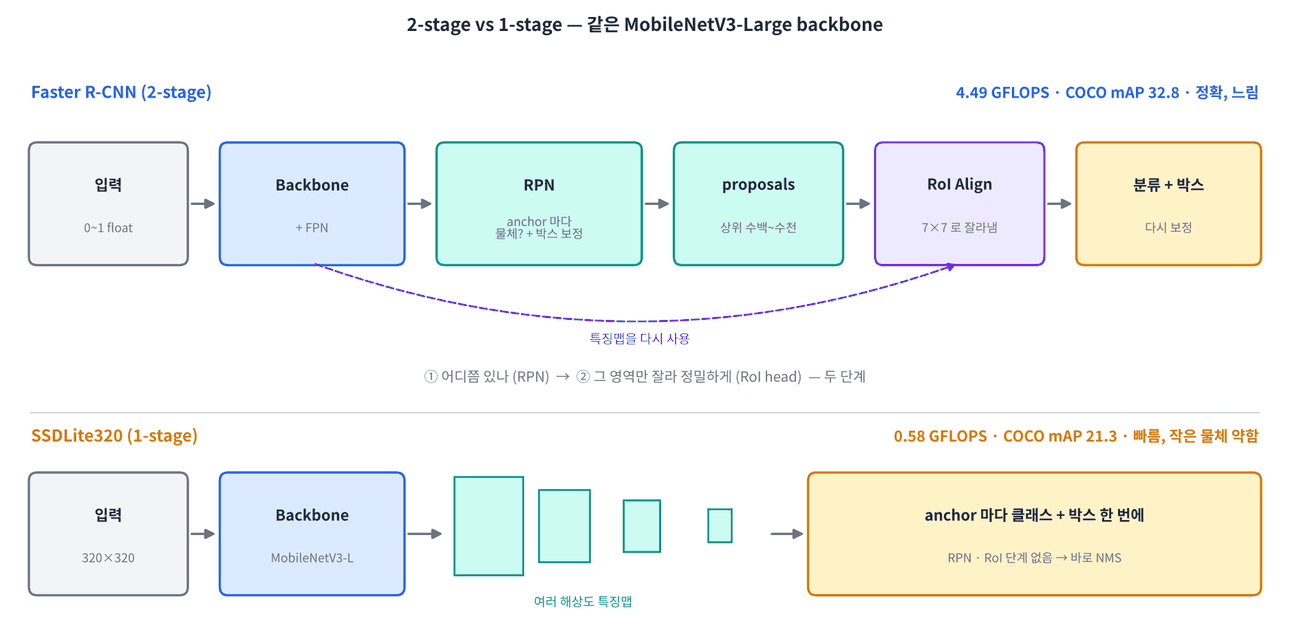

In [ ]:
#@title 🖼 그림 — 2-stage 와 1-stage 탐지기 구조
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f5_two_vs_one_stage.png", embed=True, width=860))

**문제 5-1** stride 16 특징맵의 모든 위치에 anchor 9개 (크기 64 · 128 · 256 × 비율 h/w 0.5 · 1 · 2) 를 만드는 `make_anchors` 를 완성하세요. 넓이는 크기² 를 유지합니다.

In [ ]:
def make_anchors(fh, fw, stride, sizes=(64, 128, 256), ratios=(0.5, 1.0, 2.0)):
    base = []
    for s in sizes:
        for ratio in ratios:                              # ratio = h / w, 넓이 s² 유지
            w = s / np.sqrt(ratio); h = ____
            base.append([-w / 2, -h / 2, w / 2, h / 2])
    base = np.array(base)                                 # (9, 4) — 중심 (0, 0) 기준
    cx = (np.arange(fw) + 0.5) * stride; cy = (np.arange(____) + 0.5) * stride
    cxx, cyy = np.meshgrid(cx, cy)
    centers = np.stack([cxx, cyy, cxx, cyy], -1).reshape(-1, 1, 4)
    return (centers + base[None]).reshape(-1, 4)

fh, fw = int(np.ceil(H0 / 16)), int(np.ceil(W0 / 16))
anchors = make_anchors(fh, fw, 16)
best = iou_matrix(gts[0], anchors).max(1)
print(f"특징맵 {fh}×{fw} = {fh * fw} 위치 × 9 = {len(anchors):,} anchor | 정답별 최고 IoU anchor: {best.round(3)}")

In [ ]:
a_area = (anchors[:9, 2] - anchors[:9, 0]) * (anchors[:9, 3] - anchors[:9, 1])
assert anchors.shape == (10_710, 4) and np.allclose(a_area, np.repeat([64 ** 2, 128 ** 2, 256 ** 2], 3)); print("✅")

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmRlZiBtYWtlX2FuY2hvcnMoZmgsIGZ3LCBzdHJpZGUsIHNpemVzPSg2"
    "NCwgMTI4LCAyNTYpLCByYXRpb3M9KDAuNSwgMS4wLCAyLjApKToKICAgIGJhc2UgPSBbXQogICAgZm9yIHMgaW4g"
    "c2l6ZXM6CiAgICAgICAgZm9yIHJhdGlvIGluIHJhdGlvczogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAj"
    "IHJhdGlvID0gaCAvIHcsIOuEk+ydtCBzwrIg7Jyg7KeACiAgICAgICAgICAgIHcgPSBzIC8gbnAuc3FydChyYXRp"
    "byk7IGggPSBzICogbnAuc3FydChyYXRpbykKICAgICAgICAgICAgYmFzZS5hcHBlbmQoWy13IC8gMiwgLWggLyAy"
    "LCB3IC8gMiwgaCAvIDJdKQogICAgYmFzZSA9IG5wLmFycmF5KGJhc2UpICAgICAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgIyAoOSwgNCkg4oCUIOykkeyLrCAoMCwgMCkg6riw7KSACiAgICBjeCA9IChucC5hcmFuZ2UoZncp"
    "ICsgMC41KSAqIHN0cmlkZTsgY3kgPSAobnAuYXJhbmdlKGZoKSArIDAuNSkgKiBzdHJpZGUKICAgIGN4eCwgY3l5"
    "ID0gbnAubWVzaGdyaWQoY3gsIGN5KQogICAgY2VudGVycyA9IG5wLnN0YWNrKFtjeHgsIGN5eSwgY3h4LCBjeXld"
    "LCAtMSkucmVzaGFwZSgtMSwgMSwgNCkKICAgIHJldHVybiAoY2VudGVycyArIGJhc2VbTm9uZV0pLnJlc2hhcGUo"
    "LTEsIDQpCgpmaCwgZncgPSBpbnQobnAuY2VpbChIMCAvIDE2KSksIGludChucC5jZWlsKFcwIC8gMTYpKQphbmNo"
    "b3JzID0gbWFrZV9hbmNob3JzKGZoLCBmdywgMTYpCmJlc3QgPSBpb3VfbWF0cml4KGd0c1swXSwgYW5jaG9ycyku"
    "bWF4KDEpCnByaW50KGYi7Yq57KeV66e1IHtmaH3Dl3tmd30gPSB7ZmggKiBmd30g7JyE7LmYIMOXIDkgPSB7bGVu"
    "KGFuY2hvcnMpOix9IGFuY2hvciB8IOygleuLteuzhCDstZzqs6AgSW9VIGFuY2hvcjoge2Jlc3Qucm91bmQoMyl9"
    "IikKCvCfkqEg7ZW07ISkCjU1OcOXNTM2IOydtOuvuOyngOulvCBzdHJpZGUgMTYg7Jy866GcIOykhOydtOuptCAz"
    "NMOXMzUgPSAxLDE5MCDsnITsuZgsIOychOy5mOuniOuLpCA56rCcIOKGkiAxMCw3MTAgYW5jaG9yLiDrjIDrtoDr"
    "toTsnYAg67Cw6rK97J206rOgIOygleuLteqzvCBJb1Ug6rCAIO2BsCDshozsiJjrp4wgJ+yWkeyEsScg7J20IOuQ"
    "qeuLiOuLpC4gRmFzdGVyIFItQ05OIOydgCBGUE4g7Jy866GcIOyXrOufrCDtlbTsg4Hrj4Tsl5AgYW5jaG9yIOul"
    "vCDquZTslYQg7Iuk7KCc66Gc64qUIOydtOuztOuLpCDtm6jslKwg66eO7Iq164uI64ukLiA26rWQ7IucIFlPTE92"
    "OCDsnYAgYW5jaG9yIOyXhuydtCAoYW5jaG9yLWZyZWUpIOychOy5mOyXkOyEnCDrsJXsiqQg64SkIOuzgOq5jOyn"
    "gCDqsbDrpqzrpbwg7KeB7KCRIOyYiOy4oe2VqeuLiOuLpC4="
).decode("utf-8"))

In [ ]:
# 첫 번째 사람 중심에 있는 anchor 9개와 정답 박스
cxg, cyg = (gts[0][0, 0] + gts[0][0, 2]) / 2, (gts[0][0, 1] + gts[0][0, 3]) / 2
cell = int(cyg // 16) * fw + int(cxg // 16)
vis = draw_boxes(img0, anchors[cell * 9:(cell + 1) * 9], (255, 160, 0), thick=1)
vis = draw_boxes(vis, gts[0][:1], (0, 255, 0), thick=3)
j = iou_matrix(gts[0][:1], anchors).argmax()
show([vis, draw_boxes(draw_boxes(img0, anchors[j:j + 1], (255, 0, 255), thick=2), gts[0][:1])],
     ["9 anchors at the person's center cell", f"best anchor (IoU {iou_matrix(gts[0][:1], anchors).max():.2f}) → regress to GT"], cols=2, size=4.5)

### torchvision 사전학습 탐지기

같은 **MobileNetV3-Large** backbone 을 쓰는 두 탐지기를 비교합니다 (COCO 사전학습).

| 모델 | 방식 | 파라미터 | GFLOPS | COCO box mAP |
|---|---|---|---|---|
| Faster R-CNN ResNet-50 FPN (참고) | 2-stage | 41,755,286 | 134.38 | 37.0 |
| **Faster R-CNN MobileNetV3-Large FPN** | 2-stage | 19,386,354 | 4.49 | 32.8 |
| **SSDLite320 MobileNetV3-Large** | 1-stage | 3,440,060 | 0.58 | 21.3 |

사용법: 입력은 **0~1 float 텐서의 리스트** (정규화 · 크기 조정은 모델 안에서), 출력은 이미지마다 `{"boxes": (N, 4) xyxy, "labels": (N,), "scores": (N,)}`. COCO 라벨 **1 = person** (0 은 background).

In [ ]:
from torchvision.models import detection
frcnn = detection.fasterrcnn_mobilenet_v3_large_fpn(weights="DEFAULT").eval().to(device)
ssd = detection.ssdlite320_mobilenet_v3_large(weights="DEFAULT").eval().to(device)
for name, m in [("Faster R-CNN MNv3-L FPN", frcnn), ("SSDLite320 MNv3-L", ssd)]:
    print(f"{name:24s} 파라미터 {sum(p.numel() for p in m.parameters()):>11,}")

**문제 5-2** torchvision 탐지기로 한 이미지에서 사람만 찾는 `run_tv` 를 완성하세요. RGB uint8 → (3, H, W) float 0~1, 결과에서 label 1 · 점수 ≥ 기준만 남깁니다.

In [ ]:
def run_tv(model, img, score_thr=0.5):
    x = torch.from_numpy(img).permute(2, 0, 1).float().div(____).to(device)
    with torch.no_grad():
        out = model([x])[0]                                # 이미지 리스트 → 결과 dict 리스트
    m = (out["labels"] == ____) & (out["scores"] >= score_thr)
    return out["boxes"][m].cpu().numpy(), out["scores"][m].cpu().numpy()

for name, m in [("frcnn", frcnn), ("ssd", ssd)]:
    run_tv(m, img_b)                                       # warm-up
res_tv = {}
for name, m in [("Faster R-CNN", frcnn), ("SSDLite", ssd)]:
    t0 = time.perf_counter(); bx, sc = run_tv(m, img_b); res_tv[name] = (bx, sc, (time.perf_counter() - t0) * 1000)
show([draw_boxes(img_b, gts[ib])] + [draw_boxes(img_b, bx, (255, 60, 60), [f"{s:.2f}" for s in sc]) for bx, sc, _ in res_tv.values()],
     [f"GT: {len(gts[ib])}"] + [f"{k}: {len(v[0])} people, {v[2]:.0f} ms" for k, v in res_tv.items()], cols=3, size=4)

In [ ]:
assert all(v[0].ndim == 2 and v[0].shape[1] == 4 and len(v[0]) == len(v[1]) for v in res_tv.values()); print("✅")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmRlZiBydW5fdHYobW9kZWwsIGltZywgc2NvcmVfdGhyPTAuNSk6CiAg"
    "ICB4ID0gdG9yY2guZnJvbV9udW1weShpbWcpLnBlcm11dGUoMiwgMCwgMSkuZmxvYXQoKS5kaXYoMjU1KS50byhk"
    "ZXZpY2UpCiAgICB3aXRoIHRvcmNoLm5vX2dyYWQoKToKICAgICAgICBvdXQgPSBtb2RlbChbeF0pWzBdICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAjIOydtOuvuOyngCDrpqzsiqTtirgg4oaSIOqysOqzvCBkaWN0IOum"
    "rOyKpO2KuAogICAgbSA9IChvdXRbImxhYmVscyJdID09IDEpICYgKG91dFsic2NvcmVzIl0gPj0gc2NvcmVfdGhy"
    "KQogICAgcmV0dXJuIG91dFsiYm94ZXMiXVttXS5jcHUoKS5udW1weSgpLCBvdXRbInNjb3JlcyJdW21dLmNwdSgp"
    "Lm51bXB5KCkKCmZvciBuYW1lLCBtIGluIFsoImZyY25uIiwgZnJjbm4pLCAoInNzZCIsIHNzZCldOgogICAgcnVu"
    "X3R2KG0sIGltZ19iKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICMgd2FybS11cApyZXNf"
    "dHYgPSB7fQpmb3IgbmFtZSwgbSBpbiBbKCJGYXN0ZXIgUi1DTk4iLCBmcmNubiksICgiU1NETGl0ZSIsIHNzZCld"
    "OgogICAgdDAgPSB0aW1lLnBlcmZfY291bnRlcigpOyBieCwgc2MgPSBydW5fdHYobSwgaW1nX2IpOyByZXNfdHZb"
    "bmFtZV0gPSAoYngsIHNjLCAodGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwKSAqIDEwMDApCnNob3coW2RyYXdfYm94"
    "ZXMoaW1nX2IsIGd0c1tpYl0pXSArIFtkcmF3X2JveGVzKGltZ19iLCBieCwgKDI1NSwgNjAsIDYwKSwgW2Yie3M6"
    "LjJmfSIgZm9yIHMgaW4gc2NdKSBmb3IgYngsIHNjLCBfIGluIHJlc190di52YWx1ZXMoKV0sCiAgICAgW2YiR1Q6"
    "IHtsZW4oZ3RzW2liXSl9Il0gKyBbZiJ7a306IHtsZW4odlswXSl9IHBlb3BsZSwge3ZbMl06LjBmfSBtcyIgZm9y"
    "IGssIHYgaW4gcmVzX3R2Lml0ZW1zKCldLCBjb2xzPTMsIHNpemU9NCkKCvCfkqEg7ZW07ISkCkZhc3RlciBSLUNO"
    "TiDsnYAg7ZuE67O066W8IOuLpOyLnCDrs7TripQgMuuLqOqzhCDrjZXrtoTsl5Ag6rCA66Ck7KeEIOyCrOuejCDC"
    "tyDsnpHsnYAg7IKs656M7J2EIOuNlCDsnpgg7LC+6rOgLCBTU0RMaXRlIOuKlCDsnoXroKXsnYQgMzIww5czMjAg"
    "7Jy866GcIOykhOyXrCDtlZwg67KI7JeQIOuBneuCtOuvgOuhnCDtm6jslKwg67mg66W07KeA66eMIOuGk+y5mOuK"
    "lCDsgqzrnozsnbQg7IOd6rmB64uI64ukLiAo7KeA7Jew7Iuc6rCE7J2AIOyyqyDsi6TtlokgwrcgR1BVL0NQVSDs"
    "l5Ag65Sw6528IOuLrOudvOynkeuLiOuLpCDigJQg7KCV7ZmV7ZWcIOy4oeygleydgCA36rWQ7IucIMK3IERheSA1"
    "Lik="
).decode("utf-8"))

**문제 5-3** 두 탐지기를 Penn-Fudan 170장 전체에서 4교시의 `evaluate_ap` 로 평가하세요. AP 를 계산할 때는 낮은 점수 탐지도 모두 넣습니다 (score_thr 0.05). GPU 런타임에서 1분 안팎 걸립니다 (CPU 런타임이면 앞 40장만 평가).

In [ ]:
N_EVAL = len(img_paths) if device.type == "cuda" else 40      # CPU 런타임이면 앞 40장만 (Faster R-CNN 이 CPU 에서 느림)
tv_eval = {}
for name, m in [("Faster R-CNN", frcnn), ("SSDLite", ssd)]:
    dets, t0 = [], time.perf_counter()
    for p in img_paths[:N_EVAL]:
        bx, sc = run_tv(m, load_rgb(p), score_thr=____)
        dets.append(np.concatenate([bx, sc[:, None]], 1))
    sec = time.perf_counter() - t0
    tv_eval[name] = (evaluate_ap(dets, gts[:N_EVAL], 0.5), ____, sec / N_EVAL * 1000)
    print(f"{name:13s} AP50 {tv_eval[name][0]:.4f} | mAP50-95 {tv_eval[name][1]:.4f} | {tv_eval[name][2]:.0f} ms/장 ({device})")

In [ ]:
assert len(tv_eval) == 2 and all(0 <= a <= 1 and 0 <= b <= 1 for a, b, _ in tv_eval.values()); print("✅")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACk5fRVZBTCA9IGxlbihpbWdfcGF0aHMpIGlmIGRldmljZS50eXBlID09"
    "ICJjdWRhIiBlbHNlIDQwICAgICAgIyBDUFUg65+w7YOA7J6E7J2066m0IOyVniA0MOyepeunjCAoRmFzdGVyIFIt"
    "Q05OIOydtCBDUFUg7JeQ7IScIOuKkOumvCkKdHZfZXZhbCA9IHt9CmZvciBuYW1lLCBtIGluIFsoIkZhc3RlciBS"
    "LUNOTiIsIGZyY25uKSwgKCJTU0RMaXRlIiwgc3NkKV06CiAgICBkZXRzLCB0MCA9IFtdLCB0aW1lLnBlcmZfY291"
    "bnRlcigpCiAgICBmb3IgcCBpbiBpbWdfcGF0aHNbOk5fRVZBTF06CiAgICAgICAgYngsIHNjID0gcnVuX3R2KG0s"
    "IGxvYWRfcmdiKHApLCBzY29yZV90aHI9MC4wNSkKICAgICAgICBkZXRzLmFwcGVuZChucC5jb25jYXRlbmF0ZShb"
    "YngsIHNjWzosIE5vbmVdXSwgMSkpCiAgICBzZWMgPSB0aW1lLnBlcmZfY291bnRlcigpIC0gdDAKICAgIHR2X2V2"
    "YWxbbmFtZV0gPSAoZXZhbHVhdGVfYXAoZGV0cywgZ3RzWzpOX0VWQUxdLCAwLjUpLCBtYXBfNTBfOTUoZGV0cywg"
    "Z3RzWzpOX0VWQUxdKSwgc2VjIC8gTl9FVkFMICogMTAwMCkKICAgIHByaW50KGYie25hbWU6MTNzfSBBUDUwIHt0"
    "dl9ldmFsW25hbWVdWzBdOi40Zn0gfCBtQVA1MC05NSB7dHZfZXZhbFtuYW1lXVsxXTouNGZ9IHwge3R2X2V2YWxb"
    "bmFtZV1bMl06LjBmfSBtcy/snqUgKHtkZXZpY2V9KSIpCgrwn5KhIO2VtOyEpArsp4HsoJEg66eM65OgIO2Pieqw"
    "gCDsvZTrk5zroZwg7ISc66GcIOuLpOuluCDtg5Dsp4DquLDrpbwg6rCZ7J2AIOq4sOykgOyXkOyEnCDruYTqtZDt"
    "lojsirXri4jri6QuIOuztO2GtSBGYXN0ZXIgUi1DTk4g7J20IEFQIOqwgCDrhpLqs6AgU1NETGl0ZSDqsIAg67mg"
    "66aF64uI64ukIOKAlCBDT0NPIG1BUCAzMi44IHZzIDIxLjMsIOyXsOyCsCA0LjQ5IHZzIDAuNTggR0ZMT1BTIOyZ"
    "gCDqsJnsnYAg67Cp7ZalLiDsiKvsnpDripQgQ29sYWIg7JeQ7IScIOqwgeyekCDtmZXsnbjtlZjshLjsmpQuIOye"
    "pey5mOyXkCDsmKzrprQgMS1zdGFnZSDtg5Dsp4DquLDsnZgg7ZiE7J6sIOyjvOulmOqwgCDri6TsnYwg6rWQ7Iuc"
    "7J2YIFlPTE8g7J6F64uI64ukLg=="
).decode("utf-8"))

#### 📌 5교시 정리

- anchor = 위치마다 깔아 둔 기준 박스. 모델은 점수 + 오프셋을 예측한다.
- 2-stage (RPN → RoI Align → 재분류): 정확 · 느림. 1-stage (한 번에): 빠름 · 작은 물체 약함.
- torchvision 탐지기: 입력 0~1 텐서 리스트, 출력 dict (boxes xyxy · labels · scores), person = 1.

## 6교시 — YOLO 구조: grid · 출력 텐서

**YOLO (You Only Look Once)** 는 이미지를 grid 로 나누고 칸마다 박스와 클래스를 한 번에 예측하는 1-stage 탐지기입니다.

| 부분 | 하는 일 | YOLOv8 |
|---|---|---|
| **Backbone** | 특징 추출 (Day 2 · 3 의 CNN 역할) | CSP 구조 Conv 블록 |
| **Neck** | 깊은 층 (의미) 과 얕은 층 (위치) 정보 섞기 | FPN (위→아래) + PAN (아래→위) |
| **Head** | stride 8 · 16 · 32 세 크기에서 예측 | 박스 / 클래스 분리 (decoupled), **anchor-free** |

YOLOv8 의 각 칸은 '칸 중심에서 박스 네 변까지 거리' 와 '80 클래스 점수 (sigmoid)' 를 냅니다. 버전 흐름: v1 (2016, grid) → v2 · v3 (anchor · 다중 스케일) → v4 · v5 (CSP · 증강) → **v8 (2023, anchor-free)** → 이후 버전. 커스텀 학습은 YOLOv8 Edge 모델 과목 (12/11~) 에서 합니다.

> 🎬 **애니메이션** [D4-6 YOLO grid 와 출력 텐서](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

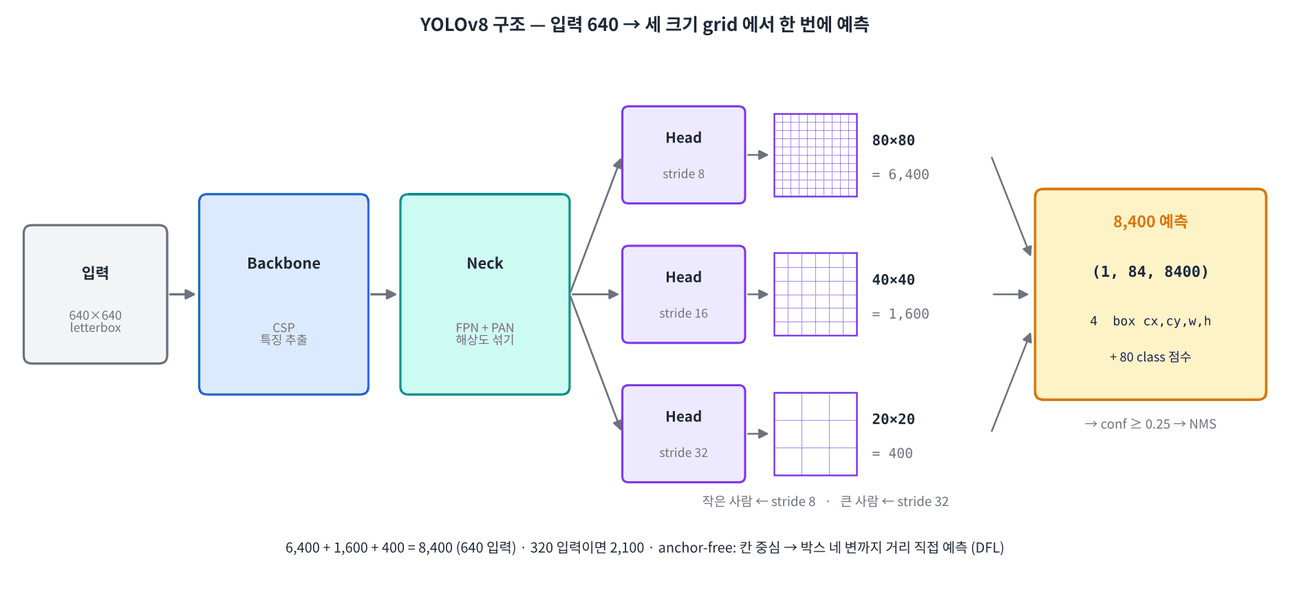

In [ ]:
#@title 🖼 그림 — YOLOv8 구조와 출력 텐서
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f6_yolo_arch.png", embed=True, width=860))

**문제 6-1** 입력 크기에 따라 YOLOv8 이 내는 예측 (칸) 개수를 계산하는 `n_preds` 를 완성하세요. stride 8 · 16 · 32 의 grid 칸 수를 모두 더합니다.

In [ ]:
def n_preds(imgsz, strides=(8, 16, 32)):
    return sum((imgsz // s) ____ 2 for s in strides)

print("640 →", n_preds(640), "| 320 →", n_preds(____))

In [ ]:
assert n_preds(640) == 8400 and n_preds(320) == 2100; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmRlZiBuX3ByZWRzKGltZ3N6LCBzdHJpZGVzPSg4LCAxNiwgMzIpKToK"
    "ICAgIHJldHVybiBzdW0oKGltZ3N6IC8vIHMpICoqIDIgZm9yIHMgaW4gc3RyaWRlcykKCnByaW50KCI2NDAg4oaS"
    "Iiwgbl9wcmVkcyg2NDApLCAifCAzMjAg4oaSIiwgbl9wcmVkcygzMjApKQoK8J+SoSDtlbTshKQKNjQwOiA4MMKy"
    "ICsgNDDCsiArIDIwwrIgPSA2LDQwMCArIDEsNjAwICsgNDAwID0gOCw0MDAg7Lm4LiAzMjAg7J2066m0IDIsMTAw"
    "IOKAlCDsmIjsuKHsnbQgMS80LCDsl7DsgrDrj4Qg7JW9IDEvNCDsnoXri4jri6QgKE1BQyDsnYAg7ZW07IOB64+E"
    "wrIg7JeQIOu5hOuhgCwgRGF5IDMpLiDsnpHsnYAg66y87LK064qUIHN0cmlkZSA4ICg4MMOXODApIOy5uOydtCwg"
    "7YGwIOusvOyytOuKlCBzdHJpZGUgMzIg7Lm47J20IOunoeyKteuLiOuLpC4="
).decode("utf-8"))

### 원시 출력을 직접 열어 보기

라이브러리의 `predict` 는 전처리 · 추론 · 후처리를 다 해 줍니다. 그 안을 직접 해 보면 Day 5 의 ONNX 모델 (후처리 없이 원시 출력만 나옴) 을 쓸 때 그대로 씁니다.

**전처리 = letterbox**: 비율을 유지한 채 긴 변을 640 에 맞춰 줄이고, 남는 곳을 회색 (114) 으로 채워 640×640 을 만듭니다. 그다음 BGR→RGB, 0~1, (1, 3, 640, 640).

**문제 6-2** `letterbox` 를 완성하고 YOLOv8n 의 원시 출력 모양을 확인하세요. 나중에 원래 좌표로 돌리려면 축소 비율 `r` 과 패딩 `(left, top)` 을 기억해야 합니다.

In [ ]:
from ultralytics import YOLO

def letterbox(img, size=640, color=114):
    h, w = img.shape[:2]
    r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    resized = cv2.resize(img, (____), interpolation=cv2.INTER_LINEAR)     # cv2 는 (폭, 높이)
    top, left = (size - nh) // 2, (____) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8)
    out[top:top + nh, left:left + nw] = resized
    return out, r, (left, top)

yolo = YOLO("yolov8n.pt")
img_bgr = cv2.imread(img_paths[ib])
lb, ratio, (padl, padt) = letterbox(img_bgr)
x = torch.from_numpy(lb[..., ::-1].copy()).permute(2, 0, 1).float().div(255)[None]     # BGR→RGB, (1, 3, 640, 640)
with torch.no_grad():
    raw = yolo.model.eval()(x)[0]                          # 원시 출력
print("원본", img_bgr.shape, "→ letterbox", lb.shape, f"r={ratio:.4f} pad=({padl}, {padt}) | 출력", tuple(raw.shape))
show([cv2.cvtColor(lb, cv2.COLOR_BGR2RGB)], ["letterbox 640x640"], cols=1, size=4)

In [ ]:
assert lb.shape == (640, 640, 3) and tuple(raw.shape) == (1, 84, 8400)
assert ratio == min(640 / img_bgr.shape[0], 640 / img_bgr.shape[1]) and ((lb[0, 0] == 114).all() or (lb[-1, -1] == 114).all()); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmZyb20gdWx0cmFseXRpY3MgaW1wb3J0IFlPTE8KCmRlZiBsZXR0ZXJi"
    "b3goaW1nLCBzaXplPTY0MCwgY29sb3I9MTE0KToKICAgIGgsIHcgPSBpbWcuc2hhcGVbOjJdCiAgICByID0gbWlu"
    "KHNpemUgLyBoLCBzaXplIC8gdykKICAgIG53LCBuaCA9IHJvdW5kKHcgKiByKSwgcm91bmQoaCAqIHIpCiAgICBy"
    "ZXNpemVkID0gY3YyLnJlc2l6ZShpbWcsIChudywgbmgpLCBpbnRlcnBvbGF0aW9uPWN2Mi5JTlRFUl9MSU5FQVIp"
    "ICAgICAjIGN2MiDripQgKO2PrSwg64aS7J20KQogICAgdG9wLCBsZWZ0ID0gKHNpemUgLSBuaCkgLy8gMiwgKHNp"
    "emUgLSBudykgLy8gMgogICAgb3V0ID0gbnAuZnVsbCgoc2l6ZSwgc2l6ZSwgMyksIGNvbG9yLCBkdHlwZT1ucC51"
    "aW50OCkKICAgIG91dFt0b3A6dG9wICsgbmgsIGxlZnQ6bGVmdCArIG53XSA9IHJlc2l6ZWQKICAgIHJldHVybiBv"
    "dXQsIHIsIChsZWZ0LCB0b3ApCgp5b2xvID0gWU9MTygieW9sb3Y4bi5wdCIpCmltZ19iZ3IgPSBjdjIuaW1yZWFk"
    "KGltZ19wYXRoc1tpYl0pCmxiLCByYXRpbywgKHBhZGwsIHBhZHQpID0gbGV0dGVyYm94KGltZ19iZ3IpCnggPSB0"
    "b3JjaC5mcm9tX251bXB5KGxiWy4uLiwgOjotMV0uY29weSgpKS5wZXJtdXRlKDIsIDAsIDEpLmZsb2F0KCkuZGl2"
    "KDI1NSlbTm9uZV0gICAgICMgQkdS4oaSUkdCLCAoMSwgMywgNjQwLCA2NDApCndpdGggdG9yY2gubm9fZ3JhZCgp"
    "OgogICAgcmF3ID0geW9sby5tb2RlbC5ldmFsKCkoeClbMF0gICAgICAgICAgICAgICAgICAgICAgICAgICMg7JuQ"
    "7IucIOy2nOugpQpwcmludCgi7JuQ67O4IiwgaW1nX2Jnci5zaGFwZSwgIuKGkiBsZXR0ZXJib3giLCBsYi5zaGFw"
    "ZSwgZiJyPXtyYXRpbzouNGZ9IHBhZD0oe3BhZGx9LCB7cGFkdH0pIHwg7Lac66ClIiwgdHVwbGUocmF3LnNoYXBl"
    "KSkKc2hvdyhbY3YyLmN2dENvbG9yKGxiLCBjdjIuQ09MT1JfQkdSMlJHQildLCBbImxldHRlcmJveCA2NDB4NjQw"
    "Il0sIGNvbHM9MSwgc2l6ZT00KQoK8J+SoSDtlbTshKQK7Lac66ClICgxLCA4NCwgODQwMCkgPSA4LDQwMCDsubgg"
    "w5cgKOuwleyKpCA0ICsgQ09DTyA4MCDtgbTrnpjsiqQg7KCQ7IiYKS4g67CV7Iqk64qUIChjeCwgY3ksIHcsIGgp"
    "IOydtOqzoCAqKmxldHRlcmJveCDrkJwgNjQwIOyeheugpeydmCDtlL3shYAg64uo7JyEKirsnoXri4jri6QuIO2B"
    "tOuemOyKpCDsoJDsiJjripQg7J2066+4IHNpZ21vaWQg66W8IOqxsOy5nCAwfjEg6rCS7J6F64uI64ukIChZT0xP"
    "djgg7JeQ64qUIOuUsOuhnCAnb2JqZWN0bmVzcycg6rCAIOyXhuyKteuLiOuLpCku"
).decode("utf-8"))

**문제 6-3** 원시 출력을 사람 박스로 바꾸는 `decode_yolo` 를 완성하세요 — 전치 → 클래스 최댓값이 점수 → conf · 클래스 필터 → cxcywh→xyxy → **직접 만든 nms**. 결과가 ultralytics `predict` 와 같은지 확인합니다.

In [ ]:
def decode_yolo(out, conf_thr=0.25, iou_thr=0.7, cls=0):
    p = out[0].T.cpu().numpy()                             # (8400, 84)
    boxes_c, cls_scores = p[:, :4], p[:, 4:]
    best, conf = cls_scores.argmax(1), cls_scores.max(1)
    m = (conf > ____) & (best == ____)
    cx, cy, w, h = boxes_c[m].T
    boxes = np.stack([cx - w / 2, cy - h / 2, ____], 1)
    keep = nms(boxes, conf[m], ____)
    return boxes[keep], conf[m][keep]

my_boxes, my_conf = decode_yolo(raw)
ref = yolo.predict(lb, imgsz=640, conf=0.25, iou=0.7, classes=[0], verbose=False)[0]     # 같은 640 입력
ref_boxes = ref.boxes.xyxy.cpu().numpy()
match = iou_matrix(my_boxes, ref_boxes).max(1) if len(ref_boxes) else np.array([])
print(f"직접 디코드 {len(my_boxes)}명 | ultralytics {len(ref_boxes)}명 | 짝 IoU 최소 {match.min() if len(match) else 0:.4f}")
orig = (my_boxes - [padl, padt, padl, padt]) / ratio                                    # letterbox 되돌리기
show([draw_boxes(load_rgb(img_paths[ib]), orig, (255, 60, 60), [f"{c:.2f}" for c in my_conf])], ["my decode → original coords"], cols=1, size=5)

In [ ]:
assert len(my_boxes) == len(ref_boxes) > 0 and match.min() > 0.99; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmRlZiBkZWNvZGVfeW9sbyhvdXQsIGNvbmZfdGhyPTAuMjUsIGlvdV90"
    "aHI9MC43LCBjbHM9MCk6CiAgICBwID0gb3V0WzBdLlQuY3B1KCkubnVtcHkoKSAgICAgICAgICAgICAgICAgICAg"
    "ICAgICAgICAgIyAoODQwMCwgODQpCiAgICBib3hlc19jLCBjbHNfc2NvcmVzID0gcFs6LCA6NF0sIHBbOiwgNDpd"
    "CiAgICBiZXN0LCBjb25mID0gY2xzX3Njb3Jlcy5hcmdtYXgoMSksIGNsc19zY29yZXMubWF4KDEpCiAgICBtID0g"
    "KGNvbmYgPiBjb25mX3RocikgJiAoYmVzdCA9PSBjbHMpCiAgICBjeCwgY3ksIHcsIGggPSBib3hlc19jW21dLlQK"
    "ICAgIGJveGVzID0gbnAuc3RhY2soW2N4IC0gdyAvIDIsIGN5IC0gaCAvIDIsIGN4ICsgdyAvIDIsIGN5ICsgaCAv"
    "IDJdLCAxKQogICAga2VlcCA9IG5tcyhib3hlcywgY29uZlttXSwgaW91X3RocikKICAgIHJldHVybiBib3hlc1tr"
    "ZWVwXSwgY29uZlttXVtrZWVwXQoKbXlfYm94ZXMsIG15X2NvbmYgPSBkZWNvZGVfeW9sbyhyYXcpCnJlZiA9IHlv"
    "bG8ucHJlZGljdChsYiwgaW1nc3o9NjQwLCBjb25mPTAuMjUsIGlvdT0wLjcsIGNsYXNzZXM9WzBdLCB2ZXJib3Nl"
    "PUZhbHNlKVswXSAgICAgIyDqsJnsnYAgNjQwIOyeheugpQpyZWZfYm94ZXMgPSByZWYuYm94ZXMueHl4eS5jcHUo"
    "KS5udW1weSgpCm1hdGNoID0gaW91X21hdHJpeChteV9ib3hlcywgcmVmX2JveGVzKS5tYXgoMSkgaWYgbGVuKHJl"
    "Zl9ib3hlcykgZWxzZSBucC5hcnJheShbXSkKcHJpbnQoZiLsp4HsoJEg65SU7L2U65OcIHtsZW4obXlfYm94ZXMp"
    "feuqhSB8IHVsdHJhbHl0aWNzIHtsZW4ocmVmX2JveGVzKX3rqoUgfCDsp50gSW9VIOy1nOyGjCB7bWF0Y2gubWlu"
    "KCkgaWYgbGVuKG1hdGNoKSBlbHNlIDA6LjRmfSIpCm9yaWcgPSAobXlfYm94ZXMgLSBbcGFkbCwgcGFkdCwgcGFk"
    "bCwgcGFkdF0pIC8gcmF0aW8gICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjIGxldHRlcmJveCDr"
    "kJjrj4zrpqzquLAKc2hvdyhbZHJhd19ib3hlcyhsb2FkX3JnYihpbWdfcGF0aHNbaWJdKSwgb3JpZywgKDI1NSwg"
    "NjAsIDYwKSwgW2Yie2M6LjJmfSIgZm9yIGMgaW4gbXlfY29uZl0pXSwgWyJteSBkZWNvZGUg4oaSIG9yaWdpbmFs"
    "IGNvb3JkcyJdLCBjb2xzPTEsIHNpemU9NSkKCvCfkqEg7ZW07ISkCuyngeygkSDrp4zrk6Ag65SU7L2U65OcICsg"
    "Tk1TIOqwgCDrnbzsnbTruIzrn6zrpqwg6rKw6rO87JmAIOqwmeydgCDrsJXsiqTrpbwg64OI7Iq164uI64ukLiDs"
    "m5Drnpgg7KKM7ZGc66GcIOuPjOumtCDrlYzripQg7Yyo65Sp7J2EIOu5vOqzoCDstpXshowg67mE7Jyo66GcIOuC"
    "mOuIleuLiOuLpCDigJQgbGV0dGVyYm94IOydmCDsl63sl7DsgrAuIERheSA1IOyXkCBPTk5YIOuhnCDrgrTrs7Tr"
    "grggWU9MTyDripQg7J20IOybkOyLnCDstpzroKXrp4wg7KO866+A66GcIOydtCDtlajsiJjqsIAg6re464yA66Gc"
    "IO2bhOyymOumrOqwgCDrkKnri4jri6Qu"
).decode("utf-8"))

**문제 6-4** YOLOv8n 과 YOLOv8s 를 비교하세요 — 파라미터 수, 같은 이미지의 결과, 단계별 시간 (`r.speed`, ms). **파라미터는 predict 전에** 셉니다 (predict 하면 Conv+BN 을 합쳐 (fuse) 숫자가 조금 줄어듭니다).

In [ ]:
yolos = {"YOLOv8n": YOLO("yolov8n.pt"), "YOLOv8s": YOLO("yolov8s.pt")}
yolo_params = {k: sum(p.numel() for p in m.model.____) for k, m in yolos.items()}
vis, titles = [], []
for k, m in yolos.items():
    m.predict(img_paths[ib], verbose=False)                # warm-up
    r = m.predict(img_paths[ib], imgsz=640, conf=0.25, classes=[____], verbose=False)[0]
    vis.append(r.plot()[..., ::-1]); titles.append(f"{k}: {len(r.boxes)} people")
    print(f"{k}: 파라미터 {yolo_params[k]:,} | " + " · ".join(f"{s} {v:.1f} ms" for s, v in r.speed.items()))
show(vis, titles, cols=2, size=4.5)

In [ ]:
assert yolo_params == {"YOLOv8n": 3_157_200, "YOLOv8s": 11_166_560}; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTQg4pSA4pSACnlvbG9zID0geyJZT0xPdjhuIjogWU9MTygieW9sb3Y4bi5wdCIpLCAi"
    "WU9MT3Y4cyI6IFlPTE8oInlvbG92OHMucHQiKX0KeW9sb19wYXJhbXMgPSB7azogc3VtKHAubnVtZWwoKSBmb3Ig"
    "cCBpbiBtLm1vZGVsLnBhcmFtZXRlcnMoKSkgZm9yIGssIG0gaW4geW9sb3MuaXRlbXMoKX0KdmlzLCB0aXRsZXMg"
    "PSBbXSwgW10KZm9yIGssIG0gaW4geW9sb3MuaXRlbXMoKToKICAgIG0ucHJlZGljdChpbWdfcGF0aHNbaWJdLCB2"
    "ZXJib3NlPUZhbHNlKSAgICAgICAgICAgICAgICAjIHdhcm0tdXAKICAgIHIgPSBtLnByZWRpY3QoaW1nX3BhdGhz"
    "W2liXSwgaW1nc3o9NjQwLCBjb25mPTAuMjUsIGNsYXNzZXM9WzBdLCB2ZXJib3NlPUZhbHNlKVswXQogICAgdmlz"
    "LmFwcGVuZChyLnBsb3QoKVsuLi4sIDo6LTFdKTsgdGl0bGVzLmFwcGVuZChmIntrfToge2xlbihyLmJveGVzKX0g"
    "cGVvcGxlIikKICAgIHByaW50KGYie2t9OiDtjIzrnbzrr7jthLAge3lvbG9fcGFyYW1zW2tdOix9IHwgIiArICIg"
    "wrcgIi5qb2luKGYie3N9IHt2Oi4xZn0gbXMiIGZvciBzLCB2IGluIHIuc3BlZWQuaXRlbXMoKSkpCnNob3codmlz"
    "LCB0aXRsZXMsIGNvbHM9Miwgc2l6ZT00LjUpCgrwn5KhIO2VtOyEpApZT0xPdjhzIOuKlCDtjIzrnbzrr7jthLDq"
    "sIAgMy4167CwLCDsl7DsgrDsnYAg7JW9IDPrsLAgKDguNyB2cyAyOC42IEdGTE9QcykuIHIuc3BlZWQg64qUIHBy"
    "ZXByb2Nlc3MgKGxldHRlcmJveCDrk7EpIMK3IGluZmVyZW5jZSDCtyBwb3N0cHJvY2VzcyAoTk1TKSDsi5zqsITs"
    "noXri4jri6QuIGByLnBsb3QoKWAg7J2AIEJHUiDqt7jrprzsnYQg7KO866+A66GcIGBbLi4uLCA6Oi0xXWAg66Gc"
    "IOuSpOynkeyWtCDtkZzsi5ztlanri4jri6Qu"
).decode("utf-8"))

#### 📌 6교시 정리

- YOLOv8 = Backbone (CSP) → Neck (FPN+PAN) → Head (stride 8 · 16 · 32, anchor-free).
- 640 입력 → 8,400 칸, 출력 (1, 84, 8400) = 박스 4 + 클래스 80.
- letterbox → 추론 → 전치 · 최댓값 · conf 필터 → xyxy → NMS → 패딩 빼고 ÷r. 직접 디코드 = 라이브러리 결과.

## 7교시 — 영상 탐지 파이프라인

Day 1 의 영상 파이프라인에 탐지를 끼웁니다.

```
VideoCapture(source) → 프레임 → 전처리 (letterbox) → 추론 → 후처리 (NMS) → 오버레이 (박스 · 인원 수) → VideoWriter
```

**규칙**: 영상은 `cv2.VideoCapture(source)` **한 곳에서만** 열고 `source` 를 인자로 받습니다. 나중에 파일 경로를 카메라 주소 (GStreamer 문자열) 로 바꾸기만 하면 Jetson · 라즈베리파이에서 그대로 돌아갑니다.

**실시간 예산**: 10 FPS 영상 → 프레임당 100 ms, 30 FPS → 33 ms 안에 모든 단계가 끝나야 합니다.

> 🎬 **애니메이션** [D4-7 프레임 파이프라인](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

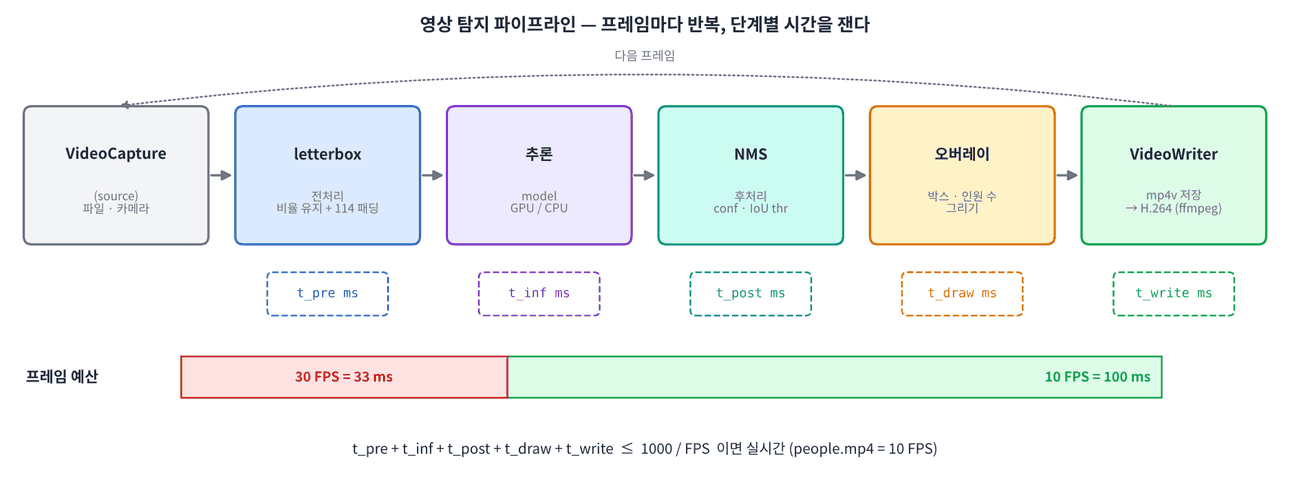

In [ ]:
#@title 🖼 그림 — 영상 탐지 파이프라인과 단계별 시간
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day4/img/f7_pipeline.png", embed=True, width=860))

In [ ]:
cap = cv2.VideoCapture(VIDEO)
V_FPS, V_N = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
V_W, V_H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.set(cv2.CAP_PROP_POS_FRAMES, 200); ok, frame200 = cap.read(); cap.release()
print(f"{VIDEO}: {V_W}×{V_H}, {V_FPS:.0f} FPS, {V_N} 프레임 ({V_N / V_FPS:.1f} 초)")
show([frame200[..., ::-1]], ["frame 200"], cols=1, size=5)

**문제 7-1** 프레임 한 장 (BGR) 에서 사람만 찾는 `detect_people` 을 완성하세요. (박스 xyxy, 점수, 단계별 시간 dict) 를 돌려줍니다.

In [ ]:
def detect_people(frame, model, imgsz=640, conf=0.25):
    r = model.predict(frame, imgsz=imgsz, conf=____, classes=[____], verbose=False)[0]
    return r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.speed

yolo_n = yolos["YOLOv8n"]
b200, s200, sp200 = detect_people(frame200, yolo_n)
print(len(b200), "명 |", {k: round(v, 1) for k, v in sp200.items()})
show([draw_boxes(frame200[..., ::-1], b200, (0, 255, 0), [f"{s:.2f}" for s in s200])], [f"frame 200: {len(b200)} people"], cols=1, size=5)

In [ ]:
assert b200.ndim == 2 and b200.shape[1] == 4 and len(b200) >= 1 and set(sp200) == {"preprocess", "inference", "postprocess"}; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmRlZiBkZXRlY3RfcGVvcGxlKGZyYW1lLCBtb2RlbCwgaW1nc3o9NjQw"
    "LCBjb25mPTAuMjUpOgogICAgciA9IG1vZGVsLnByZWRpY3QoZnJhbWUsIGltZ3N6PWltZ3N6LCBjb25mPWNvbmYs"
    "IGNsYXNzZXM9WzBdLCB2ZXJib3NlPUZhbHNlKVswXQogICAgcmV0dXJuIHIuYm94ZXMueHl4eS5jcHUoKS5udW1w"
    "eSgpLCByLmJveGVzLmNvbmYuY3B1KCkubnVtcHkoKSwgci5zcGVlZAoKeW9sb19uID0geW9sb3NbIllPTE92OG4i"
    "XQpiMjAwLCBzMjAwLCBzcDIwMCA9IGRldGVjdF9wZW9wbGUoZnJhbWUyMDAsIHlvbG9fbikKcHJpbnQobGVuKGIy"
    "MDApLCAi66qFIHwiLCB7azogcm91bmQodiwgMSkgZm9yIGssIHYgaW4gc3AyMDAuaXRlbXMoKX0pCnNob3coW2Ry"
    "YXdfYm94ZXMoZnJhbWUyMDBbLi4uLCA6Oi0xXSwgYjIwMCwgKDAsIDI1NSwgMCksIFtmIntzOi4yZn0iIGZvciBz"
    "IGluIHMyMDBdKV0sIFtmImZyYW1lIDIwMDoge2xlbihiMjAwKX0gcGVvcGxlIl0sIGNvbHM9MSwgc2l6ZT01KQ=="
).decode("utf-8"))

**문제 7-2** 영상 전체를 처리하는 `process_video` 를 완성하세요. 프레임마다 박스 · 인원 수를 그려 저장하고, 프레임별 인원 수와 단계별 평균 시간 (ms) 을 돌려줍니다.

In [ ]:
def process_video(source, out_path, model, imgsz=640, conf=0.25, max_frames=None):
    cap = cv2.VideoCapture(source)                         # 영상을 여는 곳은 여기 한 곳
    fps = cap.get(cv2.CAP_PROP_FPS)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (____))
    counts, T = [], {"read": 0.0, "preprocess": 0.0, "inference": 0.0, "postprocess": 0.0, "draw+write": 0.0}
    while True:
        t0 = time.perf_counter()
        ok, frame = cap.read()
        if not ok or (max_frames and len(counts) >= max_frames):
            break
        T["read"] += (time.perf_counter() - t0) * 1000
        boxes, scores, sp = detect_people(frame, model, imgsz, conf)
        for k in ("preprocess", "inference", "postprocess"):
            T[k] += sp[k]
        t1 = time.perf_counter()
        for (x1, y1, x2, y2), s in zip(boxes.astype(int), scores):
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(frame, f"people: {len(boxes)}", (12, 36), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (0, 0, 255), 3)
        writer.____
        T["draw+write"] += (time.perf_counter() - t1) * 1000
        counts.append(____)
    cap.release(); writer.release()
    n = max(len(counts), 1)
    return np.array(counts), {k: v / n for k, v in T.items()}

t0 = time.perf_counter()
counts_v, times_v = process_video(VIDEO, "people_det.mp4", yolo_n)
print(f"{len(counts_v)} 프레임, {time.perf_counter() - t0:.1f} 초 | 인원 최대 {counts_v.max()} · 평균 {counts_v.mean():.2f}")
print("프레임당 평균:", {k: round(v, 1) for k, v in times_v.items()}, "ms")

In [ ]:
assert len(counts_v) == V_N and os.path.getsize("people_det.mp4") > 100_000; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmRlZiBwcm9jZXNzX3ZpZGVvKHNvdXJjZSwgb3V0X3BhdGgsIG1vZGVs"
    "LCBpbWdzej02NDAsIGNvbmY9MC4yNSwgbWF4X2ZyYW1lcz1Ob25lKToKICAgIGNhcCA9IGN2Mi5WaWRlb0NhcHR1"
    "cmUoc291cmNlKSAgICAgICAgICAgICAgICAgICAgICAgICAjIOyYgeyDgeydhCDsl6zripQg6rOz7J2AIOyXrOq4"
    "sCDtlZwg6rOzCiAgICBmcHMgPSBjYXAuZ2V0KGN2Mi5DQVBfUFJPUF9GUFMpCiAgICBXLCBIID0gaW50KGNhcC5n"
    "ZXQoY3YyLkNBUF9QUk9QX0ZSQU1FX1dJRFRIKSksIGludChjYXAuZ2V0KGN2Mi5DQVBfUFJPUF9GUkFNRV9IRUlH"
    "SFQpKQogICAgd3JpdGVyID0gY3YyLlZpZGVvV3JpdGVyKG91dF9wYXRoLCBjdjIuVmlkZW9Xcml0ZXJfZm91cmNj"
    "KCoibXA0diIpLCBmcHMsIChXLCBIKSkKICAgIGNvdW50cywgVCA9IFtdLCB7InJlYWQiOiAwLjAsICJwcmVwcm9j"
    "ZXNzIjogMC4wLCAiaW5mZXJlbmNlIjogMC4wLCAicG9zdHByb2Nlc3MiOiAwLjAsICJkcmF3K3dyaXRlIjogMC4w"
    "fQogICAgd2hpbGUgVHJ1ZToKICAgICAgICB0MCA9IHRpbWUucGVyZl9jb3VudGVyKCkKICAgICAgICBvaywgZnJh"
    "bWUgPSBjYXAucmVhZCgpCiAgICAgICAgaWYgbm90IG9rIG9yIChtYXhfZnJhbWVzIGFuZCBsZW4oY291bnRzKSA+"
    "PSBtYXhfZnJhbWVzKToKICAgICAgICAgICAgYnJlYWsKICAgICAgICBUWyJyZWFkIl0gKz0gKHRpbWUucGVyZl9j"
    "b3VudGVyKCkgLSB0MCkgKiAxMDAwCiAgICAgICAgYm94ZXMsIHNjb3Jlcywgc3AgPSBkZXRlY3RfcGVvcGxlKGZy"
    "YW1lLCBtb2RlbCwgaW1nc3osIGNvbmYpCiAgICAgICAgZm9yIGsgaW4gKCJwcmVwcm9jZXNzIiwgImluZmVyZW5j"
    "ZSIsICJwb3N0cHJvY2VzcyIpOgogICAgICAgICAgICBUW2tdICs9IHNwW2tdCiAgICAgICAgdDEgPSB0aW1lLnBl"
    "cmZfY291bnRlcigpCiAgICAgICAgZm9yICh4MSwgeTEsIHgyLCB5MiksIHMgaW4gemlwKGJveGVzLmFzdHlwZShp"
    "bnQpLCBzY29yZXMpOgogICAgICAgICAgICBjdjIucmVjdGFuZ2xlKGZyYW1lLCAoeDEsIHkxKSwgKHgyLCB5Miks"
    "ICgwLCAyNTUsIDApLCAyKQogICAgICAgIGN2Mi5wdXRUZXh0KGZyYW1lLCBmInBlb3BsZToge2xlbihib3hlcyl9"
    "IiwgKDEyLCAzNiksIGN2Mi5GT05UX0hFUlNIRVlfU0lNUExFWCwgMS4xLCAoMCwgMCwgMjU1KSwgMykKICAgICAg"
    "ICB3cml0ZXIud3JpdGUoZnJhbWUpCiAgICAgICAgVFsiZHJhdyt3cml0ZSJdICs9ICh0aW1lLnBlcmZfY291bnRl"
    "cigpIC0gdDEpICogMTAwMAogICAgICAgIGNvdW50cy5hcHBlbmQobGVuKGJveGVzKSkKICAgIGNhcC5yZWxlYXNl"
    "KCk7IHdyaXRlci5yZWxlYXNlKCkKICAgIG4gPSBtYXgobGVuKGNvdW50cyksIDEpCiAgICByZXR1cm4gbnAuYXJy"
    "YXkoY291bnRzKSwge2s6IHYgLyBuIGZvciBrLCB2IGluIFQuaXRlbXMoKX0KCnQwID0gdGltZS5wZXJmX2NvdW50"
    "ZXIoKQpjb3VudHNfdiwgdGltZXNfdiA9IHByb2Nlc3NfdmlkZW8oVklERU8sICJwZW9wbGVfZGV0Lm1wNCIsIHlv"
    "bG9fbikKcHJpbnQoZiJ7bGVuKGNvdW50c192KX0g7ZSE66CI7J6ELCB7dGltZS5wZXJmX2NvdW50ZXIoKSAtIHQw"
    "Oi4xZn0g7LSIIHwg7J247JuQIOy1nOuMgCB7Y291bnRzX3YubWF4KCl9IMK3IO2Pieq3oCB7Y291bnRzX3YubWVh"
    "bigpOi4yZn0iKQpwcmludCgi7ZSE66CI7J6E64u5IO2Pieq3oDoiLCB7azogcm91bmQodiwgMSkgZm9yIGssIHYg"
    "aW4gdGltZXNfdi5pdGVtcygpfSwgIm1zIikKCvCfkqEg7ZW07ISkCm1wNHYg7L2U642x7Jy866GcIOyggOyepe2V"
    "nCDtjIzsnbzsnYAgQ29sYWIg7ZmU66m0ICjruIzrnbzsmrDsoIApIOyXkOyEnCDsnqzsg53rkJjsp4Ag7JWK7J2E"
    "IOyImCDsnojslrTshJwsIOyVhOuemCDshYDsl5DshJwgZmZtcGVnIOuhnCBILjI2NCDroZwg67CU6r+UIOyerOyD"
    "ne2VqeuLiOuLpC4g7Jm87Kq9IO2MjOydvCDtg63sl5DshJwg64K066Ck67Cb7JWEIOuztOyVhOuPhCDrkKnri4jr"
    "i6Qu"
).decode("utf-8"))

In [ ]:
def to_h264(src, dst):
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-c:v", "libx264", "-crf", "28", "-pix_fmt", "yuv420p", dst], check=True)
    return dst

def play(path, width=640):
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    return HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>')

to_h264("people_det.mp4", "people_det_h264.mp4")
plt.figure(figsize=(9, 2.6)); plt.plot(np.arange(len(counts_v)) / V_FPS, counts_v)
plt.xlabel("time (s)"); plt.ylabel("people"); plt.title("people count per frame (YOLOv8n, conf 0.25)"); plt.tight_layout(); plt.show()
display(play("people_det_h264.mp4"))

**문제 7-3** 단계별 시간을 표로 정리하고 **실시간인지** 판정하세요. GPU 런타임이면 CPU 와도 비교합니다 (CPU 는 앞 60 프레임만).

In [ ]:
def realtime_report(times, label, video_fps=V_FPS):
    total = sum(times.values())
    print(f"[{label}] " + " · ".join(f"{k} {v:.1f}" for k, v in times.items()) + f"  = {total:.1f} ms → {____:.1f} FPS"
          + ("  ✔ 실시간" if total <= ____ else "  ✘ 실시간 아님") + f" (영상 {video_fps:.0f} FPS 기준)")
    return 1000 / total

fps_main = realtime_report(times_v, str(device))
if device.type == "cuda":
    yolo_cpu = YOLO("yolov8n.pt"); yolo_cpu.predict(frame200, device="cpu", verbose=False)
    _, times_cpu = process_video(VIDEO, "tmp_cpu.mp4", yolo_cpu, max_frames=60)
    realtime_report(times_cpu, "cpu")

In [ ]:
assert fps_main > 0; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmRlZiByZWFsdGltZV9yZXBvcnQodGltZXMsIGxhYmVsLCB2aWRlb19m"
    "cHM9Vl9GUFMpOgogICAgdG90YWwgPSBzdW0odGltZXMudmFsdWVzKCkpCiAgICBwcmludChmIlt7bGFiZWx9XSAi"
    "ICsgIiDCtyAiLmpvaW4oZiJ7a30ge3Y6LjFmfSIgZm9yIGssIHYgaW4gdGltZXMuaXRlbXMoKSkgKyBmIiAgPSB7"
    "dG90YWw6LjFmfSBtcyDihpIgezEwMDAgLyB0b3RhbDouMWZ9IEZQUyIKICAgICAgICAgICsgKCIgIOKclCDsi6Ts"
    "i5zqsIQiIGlmIHRvdGFsIDw9IDEwMDAgLyB2aWRlb19mcHMgZWxzZSAiICDinJgg7Iuk7Iuc6rCEIOyVhOuLmCIp"
    "ICsgZiIgKOyYgeyDgSB7dmlkZW9fZnBzOi4wZn0gRlBTIOq4sOykgCkiKQogICAgcmV0dXJuIDEwMDAgLyB0b3Rh"
    "bAoKZnBzX21haW4gPSByZWFsdGltZV9yZXBvcnQodGltZXNfdiwgc3RyKGRldmljZSkpCmlmIGRldmljZS50eXBl"
    "ID09ICJjdWRhIjoKICAgIHlvbG9fY3B1ID0gWU9MTygieW9sb3Y4bi5wdCIpOyB5b2xvX2NwdS5wcmVkaWN0KGZy"
    "YW1lMjAwLCBkZXZpY2U9ImNwdSIsIHZlcmJvc2U9RmFsc2UpCiAgICBfLCB0aW1lc19jcHUgPSBwcm9jZXNzX3Zp"
    "ZGVvKFZJREVPLCAidG1wX2NwdS5tcDQiLCB5b2xvX2NwdSwgbWF4X2ZyYW1lcz02MCkKICAgIHJlYWx0aW1lX3Jl"
    "cG9ydCh0aW1lc19jcHUsICJjcHUiKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiCAoQ1BVLCBZT0xPdjhuIDY0MCk6"
    "IOyghOyymOumrCAyLjggbXMgwrcg7LaU66GgIDEwMi4xIG1zIMK3IO2bhOyymOumrCAxLjMgbXMg4oaSIOq3uOum"
    "rOq4sCDCtyDsoIDsnqXquYzsp4Ag7JW9IDkuMCBGUFMuIOyLnOqwhOydmCDrjIDrtoDrtoTsnYAgKirstpTroaAq"
    "KuyeheuLiOuLpC4g7J6R7J2AIOyepey5mOyXkOyEnCDruaDrpbTqsowg7ZWY66Ck66m0ICgxKSDsnoXroKUg7ZW0"
    "7IOB64+EIOuCruy2lOq4sCAoOOq1kOyLnCksICgyKSDrqqjrjbjsnYQg7KSE7J206riwLCAoMykgT05OWCDCtyBU"
    "ZW5zb3JSVCDroZwg67CU6r646riwICgxMS80fiksICg0KSBpbnQ4IOyWkeyekO2ZlCAoMTEvMTZ+KS4g7ZSE66CI"
    "7J6E66eI64ukIOuLpCDsspjrpqztlZjsp4Ag7JWK6rOgIDJ+MyDtlITroIjsnoTsl5Ag7ZWcIOuyiOunjCDtg5Ds"
    "p4DtlZjripQg6rKD64+EIO2YhOyepeyXkOyEnCDsnpDso7wg7JSB64uI64ukLg=="
).decode("utf-8"))

#### 📌 7교시 정리

- 파이프라인: VideoCapture(source) → 전처리 → 추론 → 후처리 → 오버레이 → VideoWriter. source 는 인자 하나로.
- 실시간 예산 = 1000 / FPS ms. 단계별 시간을 재서 병목 (보통 추론) 을 찾는다.
- 브라우저 재생은 H.264 (ffmpeg 변환).

## 8교시 — 미니 프로젝트: 직접 만든 mAP 로 탐지기 2종 평가 + 영상 인원 카운트

현장에 넣을 '사람 세기' 탐지기를 고릅니다. 정확도 (AP) 는 **4교시에 직접 만든 평가 코드**로, 속도는 **CPU** 에서 재고, 운영 threshold 를 정한 뒤 영상에 적용합니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 직접 만든 `evaluate_ap` · `map_50_95` 로 YOLOv8n · YOLOv8s 평가 (Penn-Fudan 170장, 640, conf 0.001) | 20 |
| 2 | 입력 해상도 320 / 640 × 모델 2종 → AP50 · mAP50-95 · CPU ms 표 | 20 |
| 3 | conf threshold 0.10~0.90 의 Precision · Recall · F1 → 운영 threshold 고르기 | 20 |
| 4 | 영상 인원 카운트 — 고른 threshold 로 결과 영상 + 프레임별 CSV | 20 |
| 5 | 결과 해석 (마크다운) | 20 (강사) |

강사 사전 실행 예 (CPU): YOLOv8n 640 AP50 0.9692 · mAP50-95 0.8357.

> 🎬 **애니메이션** [D4-8 탐지기 고르기 — threshold 와 해상도](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/animation.html#d4-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day4/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 과제 1 — 직접 만든 mAP 로 평가 (20점)

`predict_dataset(model, imgsz)` 는 170장을 예측해 이미지마다 (K, 5) [x1, y1, x2, y2, score] 배열 목록을 돌려줍니다. **AP 를 잴 때는 conf 를 아주 낮게 (0.001)** 해서 PR 곡선 전체를 얻습니다. 결과를 `res[(모델 이름, 640)]` 에 `{"dets", "AP50", "mAP"}` 로 넣으세요.

In [ ]:
def predict_dataset(model, imgsz=640, conf=0.001):
    dets = []
    for p in img_paths:
        r = model.predict(p, imgsz=imgsz, conf=conf, classes=[0], verbose=False)[0]
        dets.append(np.concatenate([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]], 1))
    return dets

res = {}
for name, m in yolos.items():
    dets = predict_dataset(m, ____)
    res[(name, 640)] = {"dets": dets, "AP50": ____, "mAP": ____}
    print(f"{name} 640 | AP50 {res[(name, 640)]['AP50']:.4f} | mAP50-95 {res[(name, 640)]['mAP']:.4f}")

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACmZvciBuYW1lLCBtIGluIHlvbG9zLml0ZW1zKCk6CiAgICBkZXRzID0g"
    "cHJlZGljdF9kYXRhc2V0KG0sIDY0MCkKICAgIHJlc1sobmFtZSwgNjQwKV0gPSB7ImRldHMiOiBkZXRzLCAiQVA1"
    "MCI6IGV2YWx1YXRlX2FwKGRldHMsIGd0cywgMC41KSwgIm1BUCI6IG1hcF81MF85NShkZXRzLCBndHMpfQ=="
).decode("utf-8"))

### 과제 2 — 해상도 × 모델 비교표 (20점)

320 입력도 평가해서 `res[(이름, 320)]` 을 채우고, 네 조합 모두 **CPU 지연시간** (`cpu_ms`, 추론 ms / 장) 을 재서 `res[...]["ms"]` 에 넣으세요. CPU 측정용 모델은 따로 불러옵니다 (GPU 에 올라간 모델과 섞이지 않게).

In [ ]:
def cpu_ms(weights, imgsz, n=15):
    m = YOLO(weights)
    m.predict(img_paths[0], imgsz=imgsz, device="cpu", verbose=False)              # warm-up
    return float(np.mean([m.predict(p, imgsz=imgsz, device="cpu", verbose=False)[0].speed["inference"] for p in img_paths[:n]]))

for name, m in yolos.items():
    dets = predict_dataset(m, ____)
    res[(name, 320)] = {"dets": dets, "AP50": evaluate_ap(dets, gts, 0.5), "mAP": map_50_95(dets, gts)}
for (name, sz) in res:
    res[(name, sz)]["ms"] = cpu_ms(name.lower() + ".pt", ____)
print(f"{'모델':8s} {'입력':>5s} {'AP50':>7s} {'mAP50-95':>9s} {'CPU ms':>8s}")
for (name, sz), v in sorted(res.items()):
    print(f"{name:8s} {sz:5d} {v['AP50']:7.4f} {v['mAP']:9.4f} {v['ms']:8.1f}")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACmZvciBuYW1lLCBtIGluIHlvbG9zLml0ZW1zKCk6CiAgICBkZXRzID0g"
    "cHJlZGljdF9kYXRhc2V0KG0sIDMyMCkKICAgIHJlc1sobmFtZSwgMzIwKV0gPSB7ImRldHMiOiBkZXRzLCAiQVA1"
    "MCI6IGV2YWx1YXRlX2FwKGRldHMsIGd0cywgMC41KSwgIm1BUCI6IG1hcF81MF85NShkZXRzLCBndHMpfQpmb3Ig"
    "KG5hbWUsIHN6KSBpbiByZXM6CiAgICByZXNbKG5hbWUsIHN6KV1bIm1zIl0gPSBjcHVfbXMobmFtZS5sb3dlcigp"
    "ICsgIi5wdCIsIHN6KQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiCAoQ1BVKTogWU9MT3Y4biA2NDAgMC45NjkyIC8g"
    "MC44MzU3IC8gMTIxIG1zIMK3IFlPTE92OHMgNjQwIDAuOTY2MyAvIDAuODQ5OCAvIDI5OCBtcyDCtyBZT0xPdjhu"
    "IDMyMCAwLjk3NDEgLyAwLjgxNTkgLyAzOCBtcyDCtyBZT0xPdjhzIDMyMCAwLjk2NzQgLyAwLjgzODEgLyA5OSBt"
    "cy4="
).decode("utf-8"))

### 과제 3 — 운영 threshold 고르기 (20점)

AP 는 모든 threshold 의 요약이지만, 현장에서는 **threshold 하나**로 돌립니다. YOLOv8n 640 의 탐지 (`res[("YOLOv8n", 640)]["dets"]`) 에서 conf 0.10, 0.15, …, 0.90 마다 그 이상인 탐지만 남겨 IoU 0.5 기준 Precision · Recall · F1 (= 2PR / (P + R)) 을 구하고, **F1 이 가장 큰 conf** 를 `best_conf` 로 고르세요.

In [ ]:
CONFS = np.round(np.arange(0.10, 0.91, 0.05), 2)
dets_n = res[("YOLOv8n", 640)]["dets"]
P_c, R_c, F1_c = [], [], []
for c in CONFS:
    kept = [d[d[:, 4] >= ____] for d in dets_n]
    _, tp, n_gt = match_detections(kept, gts, 0.5)
    n_det = len(tp)
    P = tp.sum() / max(n_det, 1); Rc = tp.sum() / ____
    P_c.append(P); R_c.append(Rc); F1_c.append(2 * P * Rc / max(P + Rc, 1e-12))
P_c, R_c, F1_c = map(np.array, (P_c, R_c, F1_c))
best_conf = float(CONFS[____])
plt.figure(figsize=(6, 3.5))
for v, lab in [(P_c, "precision"), (R_c, "recall"), (F1_c, "F1")]: plt.plot(CONFS, v, "o-", ms=3, label=lab)
plt.axvline(best_conf, ls="--", c="gray"); plt.xlabel("conf threshold"); plt.legend(); plt.title(f"YOLOv8n 640 — best F1 at conf {best_conf}"); plt.show()
print(f"best conf {best_conf} | P {P_c[CONFS == best_conf][0]:.4f} R {R_c[CONFS == best_conf][0]:.4f} F1 {F1_c.max():.4f}")

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmZvciBjIGluIENPTkZTOgogICAga2VwdCA9IFtkW2RbOiwgNF0gPj0g"
    "Y10gZm9yIGQgaW4gZGV0c19uXQogICAgXywgdHAsIG5fZ3QgPSBtYXRjaF9kZXRlY3Rpb25zKGtlcHQsIGd0cywg"
    "MC41KQogICAgbl9kZXQgPSBsZW4odHApCiAgICBQID0gdHAuc3VtKCkgLyBtYXgobl9kZXQsIDEpOyBSYyA9IHRw"
    "LnN1bSgpIC8gbl9ndAogICAgUF9jLmFwcGVuZChQKTsgUl9jLmFwcGVuZChSYyk7IEYxX2MuYXBwZW5kKDIgKiBQ"
    "ICogUmMgLyBtYXgoUCArIFJjLCAxZS0xMikpCmJlc3RfY29uZiA9IGZsb2F0KENPTkZTW25wLmFyZ21heChGMV9j"
    "KV0pCgrwn5KhIO2VtOyEpApjb25mIOulvCDsmKzrpqzrqbQgUmVjYWxsIOydgCDspITslrTrk6TquLDrp4wg7ZWY"
    "6rOgICjtmZXsnbgg7IWA7J20IOqygOyCrCksIFByZWNpc2lvbiDsnYAg64yA7LK066GcIOyYpOumheuLiOuLpC4g"
    "7Iuk7ZaJIOyYiDogRjEg7LWc64yAIGNvbmYgMC43IChQIDAuODkyMywgUiAwLjk1OTgsIEYxIDAuOTI0OCkuIFBl"
    "bm4tRnVkYW4g7J2AIOygleuLteyXkOyEnCDruaDsp4Qg7J6R7J2AIMK3IOqwgOugpOynhCDsgqzrnozsnbQg7J6I"
    "7Ja0IOyLpOygnOuztOuLpCBQcmVjaXNpb24g7J20IOuCruqyjCDrgpjsmLXri4jri6QuICftlZwg66qF64+EIOuG"
    "k+y5mOuptCDslYgg65CY64qUJyDsnITtl5jqtazsl60g6rCQ7Iuc652866m0IEYxIOy1nOuMgOuztOuLpCBjb25m"
    "IOulvCDrgq7strAgUmVjYWxsIOydhCDsmrDshKDtlanri4jri6Qu"
).decode("utf-8"))

### 과제 4 — 영상 인원 카운트 (20점)

YOLOv8n · 640 · `best_conf` 로 `people.mp4` 전체를 처리해 `count_result.mp4` 로 저장하고, 프레임별 인원 수를 `people_count.csv` (열: frame, time_s, count) 로 저장하세요.

In [ ]:
counts_p, times_p = process_video(____, "count_result.mp4", yolo_n, imgsz=640, conf=____)
with open("people_count.csv", "w") as f:
    f.write("frame,time_s,count\n")
    for i, c in enumerate(counts_p):
        f.write(f"{i},{i / V_FPS:.1f},{____}\n")
print(f"{len(counts_p)} 프레임 | 최대 {counts_p.max()} 명 · 평균 {counts_p.mean():.2f} 명")
to_h264("count_result.mp4", "count_result_h264.mp4")
plt.figure(figsize=(9, 2.6)); plt.plot(np.arange(len(counts_p)) / V_FPS, counts_p); plt.xlabel("time (s)"); plt.ylabel("people"); plt.tight_layout(); plt.show()
display(play("count_result_h264.mp4"))

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmNvdW50c19wLCB0aW1lc19wID0gcHJvY2Vzc192aWRlbyhWSURFTywg"
    "ImNvdW50X3Jlc3VsdC5tcDQiLCB5b2xvX24sIGltZ3N6PTY0MCwgY29uZj1iZXN0X2NvbmYpCndpdGggb3Blbigi"
    "cGVvcGxlX2NvdW50LmNzdiIsICJ3IikgYXMgZjoKICAgIGYud3JpdGUoImZyYW1lLHRpbWVfcyxjb3VudFxuIikK"
    "ICAgIGZvciBpLCBjIGluIGVudW1lcmF0ZShjb3VudHNfcCk6CiAgICAgICAgZi53cml0ZShmIntpfSx7aSAvIFZf"
    "RlBTOi4xZn0se2N9XG4iKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDogNzk1IO2UhOugiOyehCwg7LWc64yAIDgg"
    "66qFLCDtj4nqt6AgNC45NiDrqoUuIOq3uOuemO2UhOqwgCDtlITroIjsnoTrp4jri6QgwrExfjLrqoXslKkg7Lac"
    "66CB7J2064qUIOqyg+ydgCDqsIDroKTsp4Qg7IKs656M7J20IOyeoe2YlOuLpCDslYgg7J6h7ZiU64ukIO2VmOq4"
    "sCDrlYzrrLjsnoXri4jri6Qg4oCUIO2YhOyepeyXkOyEnOuKlCDrqocg7ZSE66CI7J6EIO2Pieq3oCDCtyDstpTs"
    "oIEgKHRyYWNraW5nKSDsnLzroZwg7JWI7KCV7ZmU7ZWp64uI64ukLg=="
).decode("utf-8"))

### 과제 5 — 결과 해석 (강사 20점)

1. 비교표에서 **라즈베리파이급 장치에 올릴 조합** (모델 · 입력 크기) 을 고르고 AP50 · mAP50-95 · CPU ms 숫자로 근거를 대세요.
2. 네 조합의 **AP50 차이와 mAP50-95 차이** 중 어느 쪽이 더 큰가? 왜 그런가? (Penn-Fudan 의 박스 크기 — 1교시 문제 1-2)
3. 고른 conf 에서 Precision 이 1 이 아닌 이유를 정답 데이터의 특징과 함께 설명하세요. (2교시 문제 2-2)
4. 공사 현장 출입 인원 세기 · 위험구역 침입 감지 각각에 conf 를 높일까 낮출까?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4g7Iuk7ZaJIOyYiDogWU9MT3Y4biAzMjAg7J2AIEFQNTAgMC45NzQxIOuh"
    "nCA2NDAg7J2YIOuqqOuNuOuTpOqzvCDqsbDsnZgg6rCZ7Jy866m07IScIENQVSAzOCBtcyDroZwg6rCA7J6lIOu5"
    "oOultOuLpCAoWU9MT3Y4cyA2NDAgMjk4IG1zKS4g7IKs656M7J20IO2BrOqyjCDssI3tnojripQg7ZmU66m07J20"
    "66m0IFlPTE92OG4gMzIwLCDrqYDrpqwg7J6I64qUIOyekeydgCDsgqzrnozquYzsp4Ag7IS47JW8IO2VmOuptCA2"
    "NDAgKOuYkOuKlCDqt7gg7J207IOBKSDsnbQg7ZWE7JqU7ZWY64ukLiDsnqXsuZjsl5DshJwg64uk7IucIOyerOyE"
    "nCDqsrDsoJUgKERheSA1IMK3IE9OTlggwrcgVGVuc29yUlQpLgoyLiBBUDUwIOydgCDrhKQg7KGw7ZWp7J20IDAu"
    "OTcg7JWI7YyO7Jy866GcIOqxsOydmCDqsJnqs6AgKDAuOTY2MyB+IDAuOTc0MSDigJQgMzIwIOydtCDsmKTtnojr"
    "oKQg7JW96rCEIOuGkuq4sOuPhCDtlZjri6QpLCDssKjsnbTripQgbUFQNTAtOTUgKDAuODE1OSB+IDAuODQ5OCkg"
    "7JeQ7IScIOuTnOufrOuCnOuLpC4gUGVubi1GdWRhbiDsnZgg7IKs656M7J2AIOyImOuwsSDtlL3shYDroZwg7Luk"
    "7IScIOyekeydgCDrqqjrjbggwrcg64Ku7J2AIO2VtOyDgeuPhOuhnOuPhCAn7LC+6riwJyDripQg7Lap67aE7ZWY"
    "6rOgLCDtgbAg66qo6424IMK3IOuGkuydgCDtlbTsg4Hrj4TripQgJ+uwleyKpCDsnITsuZjrpbwg642UIOygle2Z"
    "le2eiCcg66ee7Z6I64qUIOuNsCDsnbTrk53snbQg7J6I64ukLgozLiDsoJXri7Xsl5Ag7JeG64qUIOyekeydgCDC"
    "tyDqsIDroKTsp4Qg7IKs656M7J2EIO2DkOyngOq4sOqwgCDrp57qsowg7LC+7Jy866m0IEZQIOuhnCDqs4TsgrDr"
    "kJjqs6AsIOqyuey5nCDsgqzrnowgwrcg7IKs656M7J2YIOydvOu2gCAo7IOB67CY7IugKSDrpbwg65Sw66GcIOye"
    "oeuKlCDqsr3smrDrj4Qg7J6I64ukLiDsp4DtkZzripQg7KCV64u17J2YIO2SiOyniOunjO2BvOunjCDrr7/snYQg"
    "7IiYIOyeiOuLpC4KNC4g7Lac7J6FIOyduOybkCDshLjquLDripQg6rO864yAIOqzhOyImOuPhCDrrLjsoJzrnbwg"
    "RjEg7LWc64yAIOq3vOyymC4g7JyE7ZeY6rWs7JetIOy5qOyeheydgCDrhpPsuZjrqbQg7IKs6rOg7J2066+A66Gc"
    "IGNvbmYg66W8IOuCruy2sCBSZWNhbGwg7J2EIOyasOyEoO2VmOqzoCwg7Jik6rK967O064qUIOyXrOufrCDtlITr"
    "oIjsnoQg7Jew7IaNIOyhsOqxtCDCtyBST0kg66GcIOykhOyduOuLpCAoRGF5IDUpLg=="
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    for n in ("YOLOv8n", "YOLOv8s"):
        v = res[(n, 640)]; assert len(v["dets"]) == 170 and v["AP50"] >= 0.9 and 0.5 < v["mAP"] < v["AP50"]
    assert np.isclose(res[("YOLOv8n", 640)]["AP50"], evaluate_ap(res[("YOLOv8n", 640)]["dets"], gts, 0.5))
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    assert len(res) == 4 and all({"AP50", "mAP", "ms"} <= set(v) and v["ms"] > 0 and 0 < v["mAP"] < 1 for v in res.values())
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    assert len(CONFS) == 17 and len(P_c) == len(R_c) == len(F1_c) == 17 and np.all(np.diff(R_c) <= 1e-12)
    assert best_conf in CONFS and np.isclose(F1_c[list(CONFS).index(best_conf)], F1_c.max())
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    rows = open("people_count.csv").read().strip().splitlines()
    assert len(counts_p) == V_N and len(rows) == V_N + 1 and rows[0] == "frame,time_s,count" and os.path.getsize("count_result.mp4") > 100_000
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
print(f"\n자동 채점 {score} / 80  (과제 5 해석은 강사 채점 20점)")

### 🔎 더 알아보기

과제 5 를 제출한 뒤에 보세요. ultralytics 에는 평가 기능 (`model.val`) 이 들어 있지만 COCO 형식 데이터 · YAML 설정이 필요하고 내부 계산이 보이지 않습니다. 오늘 만든 `iou_nms_map.py` 는 어떤 탐지기 (torchvision · YOLO · ONNX · TensorRT) 의 결과에도 똑같이 쓸 수 있어, 다음 과목에서 **변환 · 양자화 전후의 정확도가 떨어졌는지** 확인하는 도구가 됩니다.

#### 📌 8교시 정리

- 평가 코드를 직접 가지고 있으면 어떤 탐지기든 같은 기준으로 비교할 수 있다.
- AP50 이 같아도 mAP50-95 · 속도가 다르다. 데이터의 물체 크기에 맞는 해상도를 고른다.
- 운영 threshold 는 F1 과 현장 목적 (놓침 vs 오경보) 으로 정한다.

## 오늘의 정리

### 셀프 체크

- [ ] 분류와 탐지의 출력 차이, sliding window 가 느린 이유를 말할 수 있다
- [ ] xyxy · xywh · 정규화 cxcywh 를 서로 바꾸고 COCO JSON 을 만들 수 있다
- [ ] IoU 와 NMS 를 NumPy 로 구현하고 torchvision 과 맞출 수 있다
- [ ] Precision · Recall · AP (envelope 넓이) · mAP50-95 를 손으로 · 코드로 계산할 수 있다
- [ ] anchor, 2-stage (RPN · RoI Align) 와 1-stage 의 차이를 설명할 수 있다
- [ ] YOLOv8 원시 출력 (1, 84, 8400) 을 letterbox 역변환까지 디코드할 수 있다
- [ ] 영상 탐지 파이프라인을 만들고 단계별 시간으로 실시간 여부를 판정할 수 있다

### 다음 시간 (Day 5 · 11/3 화) 예고

박스로는 부족한 상황 — 위험구역 **경계를 넘었나**, 사람이 **쓰러졌나**. 픽셀 단위 **세그멘테이션**과 관절 단위 **포즈**를 다루고, 모델을 **ONNX** 로 내보내 CPU 성능을 측정합니다. 마지막에 **위험구역 침입 감지** (영상 → 결과 영상 + 로그) 를 만듭니다.